# TGLS Anomaly Detection and Diagnosis
Apply Mahalanobis distance and a CNN autoencoder separately to 12 component sensors and 3 bearing response channels (Pb, Tb, Vib).

Use the complete all-normal record to establish each normal reference. Only one all-normal test is available: independent false-alarm performance is not evaluated. Evaluate the remaining 80 component-fault conditions. Bearing departures from the reference do not establish bearing damage.

Stored condition labels: **0 = normal, 1 = moderate, 2 = severe**. The code.mat values have been recoded from the previous reversed convention; case order and measured data are unchanged. Run the notebook from the top.

# Settings and utilities

## Plot settings and data paths

In [ ]:
import matplotlib.pyplot as plt
from google.colab import drive
from pathlib import Path

# Set common plot font sizes
plt.rcParams.update(
    {
        "font.size": 16,
        "axes.titlesize": 18,
        "axes.labelsize": 16,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "legend.fontsize": 14,
        "figure.titlesize": 18,
    }
)

# Mount Google Drive and set the dataset root
# Change DATA_ROOT here if the practice folder is renamed or moved
drive.mount("/content/drive")
DATA_ROOT = Path("/content/drive/MyDrive/PHM Practice/Datasets")
PROJECT_ROOT = DATA_ROOT.parent

Mounted at /content/drive


## Shared utility functions

In [ ]:
import numpy as np
import pandas as pd

# Purpose: format displayed numbers without changing their stored values.
# Input: value (number); spec (optional standard Python format).
# Output: formatted text; the input value remains unchanged.
# Used in: anomaly detection and subsequent diagnosis sections.
def format_number(value, spec=""):
    import numbers

    if not isinstance(value, numbers.Real):
        return format(value, spec)
    value = float(value)
    if spec.endswith(("e", "E", "g", "G", "%")):
        return format(value, spec)
    if 0 < abs(value) < 0.001:
        return f"{value:.3e}"
    precision = 3 if abs(value) < 10 else 2
    import re

    pattern = re.sub(r"\.\d+f$", f".{precision}f", spec) if spec else f".{precision}f"
    return format(value, pattern)

# Format displayed numbers without changing stored values.
np.set_printoptions(formatter={"float_kind": format_number})
pd.options.display.float_format = format_number


# Purpose: report abnormal-condition scores for either anomaly detector.
# Input: detector results, method name; uses shared test labels and window data.
# Output: test-level summary table and distance/error plots; no false-alarm metrics.
# Used in: Mahalanobis distance and autoencoder.
def show_anomaly_results(detector_results, method_name):
    summary = case_table.copy()
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    window_numbers = np.arange(1, n_windows + 1)
    for row, (group, result) in enumerate(detector_results.items()):
        scores, threshold = result['scores'], result['threshold']
        fractions = (scores[fault_cases] > threshold).mean(axis=1)
        column = group + ' threshold-exceedance fraction'
        summary[column] = np.nan
        summary.loc[fault_cases, column] = fractions
        print(f'\n{method_name} / {group}')
        print(f'Normal reference tests: 1; reference windows: {n_windows}')
        print(f'Component-fault tests: {len(fault_cases)}; evaluated windows: {len(fault_cases) * n_windows}')
        print('Threshold:', format_number(threshold))
        rate = np.mean(scores[fault_cases] > threshold)
        label = ('Component fault detection rate' if group == 'Component'
                 else 'Bearing reference-deviation fraction under component faults')
        print(label + ':', format_number(rate))
        print('Independent false-alarm rate: not evaluated')
        ax = axes[row, 0]
        ax.plot(window_numbers, scores[normal_case], marker='o', markersize=4, linestyle='-', label=f'Normal reference: case {normal_case + 1}')
        ax.axhline(threshold, color='r', linestyle='--', label='Threshold')
        ax.set(title=f'{group}: complete normal reference', xlabel='Window number', ylabel=method_name + ' score')
        ax.set_xlim(0.5, n_windows + 0.5)
        ax.grid(True); ax.legend(fontsize=11)
        ax = axes[row, 1]
        ax.bar(fault_cases + 1, fractions)
        ax.set(title=group + ': component-fault conditions', xlabel='Case number',
               ylabel='Threshold-exceedance fraction', ylim=(0, 1.05))
        ax.grid(axis='y')
    plt.tight_layout(); plt.show()
    display(summary)
    return summary


# Purpose: report model layers, parameter counts, and subset sizes.
# Input: model (Keras/PyTorch model), training/validation inputs, optional test.
# Output: printed model structure, parameter counts, and data shapes.
# Used in: machine learning method.
def show_model_info(model, training, validation, test=None):
    # Purpose: return the shapes of one or more model inputs.
    # Input: data.
    # Output: returned [tuple(value.shape) for value in values].
    def sample_shape(data):
        values = data if isinstance(data, (list, tuple)) else [data]
        return [tuple(value.shape) for value in values]

    # Purpose: return the number of samples in the model inputs.
    # Input: data.
    # Output: returned len(value).
    def sample_count(data):
        value = data[0] if isinstance(data, (list, tuple)) else data
        return len(value)

    print("Model structure")
    if hasattr(model, "summary"):
        model.summary()
        import numpy as np

        trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
        total = model.count_params()
    else:
        print(model)
        total = sum(p.numel() for p in model.parameters())
        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Parameters: {total:,} total; {trainable:,} trainable")
    print(f"Training samples: {sample_count(training):,}")
    print(f"Validation samples: {sample_count(validation):,}")
    print("Training input shapes:", sample_shape(training))
    print("Validation input shapes:", sample_shape(validation))
    if test is not None:
        print(f"Test samples: {sample_count(test):,}")
        print("Test input shapes:", sample_shape(test))


# Purpose: create a callback that reports training and validation losses.
# Input: every (epoch interval, default 100).
# Output: Keras callback for progress reporting.
# Used in: machine learning method.
def training_progress(every=100):
    from tensorflow.keras.callbacks import LambdaCallback

    # Purpose: print training and validation loss at the selected epoch interval.
    # Input: epoch, logs.
    # Output: updated state or displayed result; no return value.
    def report(epoch, logs):
        if epoch == 0 or (epoch + 1) % every == 0:
            loss = format_number(logs.get("loss", float("nan")))
            valid = format_number(logs.get("val_loss", float("nan")))
            print(f"Epoch {epoch + 1}: training loss={loss}; validation loss={valid}")

    return LambdaCallback(on_epoch_end=report)


# Purpose: report completed epochs, best losses, and elapsed training time.
# Input: history (Keras history), started (time.perf_counter timestamp).
# Output: printed training summary.
# Used in: machine learning method.
def report_training(history, started):
    import time
    import numpy as np

    losses = history.history
    reference = losses.get("val_loss", losses["loss"])
    best = int(np.argmin(reference))
    print(f'Completed epochs: {len(losses["loss"])}; best epoch: {best + 1}')
    print("Best training loss:", format_number(losses["loss"][best]))
    if "val_loss" in losses:
        print("Best validation loss:", format_number(losses["val_loss"][best]))
    print("Training time:", format_number(time.perf_counter() - started), "s")


# Purpose: build the three common TGLS feature variants for binary/severity diagnosis and BN.
# Input: windows (cases, windows, samples, channels), component sensor columns,
#        sensor names, training case IDs, and denominator-floor fraction.
# Output: dictionaries for 24/32/44-feature arrays and names, flow floor and affected fraction.
# Used in: binary ANN, severity ANN and BN feature preparation.
def extract_tgls_feature_sets(windows, component_channels, names, training_cases, flow_floor_fraction=0.01):
    sensor_values = windows[..., component_channels]
    differences = np.stack([windows[..., 1] - windows[..., 0],
        windows[..., 1] - windows[..., 2], windows[..., 2] - windows[..., 3],
        windows[..., 7] - windows[..., 8]], axis=-1)
    difference_names = ['Pump P2-P1', 'Filter P2-P3', 'Cooler P3-P4', 'Cooling T3-T4']
    flow = windows[..., 12]
    positive_training_flow = flow[training_cases]
    positive_training_flow = positive_training_flow[positive_training_flow > 0]
    assert len(positive_training_flow) > 0
    floor = max(flow_floor_fraction * float(np.median(positive_training_flow)), 1e-8)
    denominator = np.maximum(flow, floor)
    proxies = np.stack([windows[..., 10] * differences[..., 0],
        differences[..., 1] / denominator, differences[..., 1] / denominator ** 2,
        differences[..., 2] / denominator, differences[..., 2] / denominator ** 2,
        flow * differences[..., 3]], axis=-1)
    proxy_names = ['Pump Q*(P2-P1)', 'Filter (P2-P3)/Q', 'Filter (P2-P3)/Q^2',
        'Cooler (P3-P4)/Q', 'Cooler (P3-P4)/Q^2', 'Cooling Q*(T3-T4)']
    blocks, block_names = [], []
    for values, channel_names in [(sensor_values, [names[i] for i in component_channels]),
                                  (differences, difference_names), (proxies, proxy_names)]:
        blocks.append(np.concatenate([values.mean(axis=2), values.std(axis=2)], axis=-1))
        block_names.append([name + '-Mean' for name in channel_names]
                           + [name + '-STD' for name in channel_names])
    feature_sets, feature_names = {}, {}
    for mode, count in [(24, 1), (32, 2), (44, 3)]:
        feature_sets[mode] = np.concatenate(blocks[:count], axis=-1)
        feature_names[mode] = sum(block_names[:count], [])
        assert feature_sets[mode].shape[-1] == len(feature_names[mode]) == mode
        assert np.isfinite(feature_sets[mode]).all()
    return feature_sets, feature_names, floor, float(np.mean(flow < floor))


# Read TGLS data

In [ ]:
from scipy.io import loadmat
from IPython.display import display

# User settings: stored labels are 0=normal, 1=moderate, 2=severe.
NORMAL_LEVEL = 0

# Read the original MAT variables without changing either source file.
data_dir = DATA_ROOT / 'TGLS'
file_path = data_dir / 'data.mat'
data = loadmat(file_path)['data'].astype(np.float32)
file_path = data_dir / 'code.mat'
condition_code = loadmat(file_path)['code'].astype(int)

# Map sensor columns and component condition columns to their physical roles.
sensor_names = ['P1', 'P2', 'P3', 'P4', 'Pb', 'T1', 'T2', 'T3', 'T4', 'T5',
                'F1', 'Tb', 'F3', 'F5', 'Vib']
fault_names = ['Pump', 'Filter blockage', 'Cooler blockage', 'Cooler']
component_idx = [0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 12, 13]
bearing_idx = [4, 11, 14]
groups = {'Component': component_idx, 'Bearing': bearing_idx}
# Check array dimensions and locate the all-normal test.
assert data.ndim == 3 and data.shape[1] == 15
assert condition_code.shape == (data.shape[2], 4)
assert np.isfinite(data).all() and np.isin(condition_code, [0, 1, 2]).all()
normal_cases = np.flatnonzero(np.all(condition_code == NORMAL_LEVEL, axis=1))
assert len(normal_cases) == 1, 'Review the split for multiple normal tests.'
normal_case = int(normal_cases[0])
# Display the array structure, sensor mapping and test conditions.
print('data:', data.shape, '(samples, sensors, cases)')
print('condition_code:', condition_code.shape, '(cases, fault modes)')
print('Normal case (1-based):', normal_case + 1)
display(pd.DataFrame({'Sensor number': np.arange(1, 16), 'Sensor': sensor_names,
                      'Group': ['Bearing' if i in bearing_idx else 'Component' for i in range(15)]}))
case_table = pd.DataFrame(condition_code, columns=fault_names)
case_table.insert(0, 'Case', np.arange(1, len(condition_code) + 1))
display(case_table)


data: (17400, 15, 81) (samples, sensors, cases)
condition_code: (81, 4) (cases, fault modes)
Normal case (1-based): 28


,Sensor number,Sensor,Group
0,1,P1,Component
1,2,P2,Component
2,3,P3,Component
3,4,P4,Component
4,5,Pb,Bearing
5,6,T1,Component
6,7,T2,Component
7,8,T3,Component
8,9,T4,Component
9,10,T5,Component


,Case,Pump,Filter blockage,Cooler blockage,Cooler
0,1,0,0,0,1
1,2,0,0,2,0
2,3,0,0,2,2
3,4,0,1,1,0
4,5,0,1,1,2
...,...,...,...,...,...
76,77,2,2,0,1
77,78,2,2,0,2
78,79,2,2,1,1
79,80,2,2,1,2


## Compare all-normal and all-fault raw sensor signals
Show only the 12 component sensors: P1-P4, T1-T5, F1/F3/F5. Compare all-normal case 28 on the left with all-severe case 27 on the right. Pressure, temperature and flow occupy separate rows with matched left/right scales. Bearing responses Pb, Tb and Vib are shown separately below. Use original recorded values; units and sampling frequency remain unconfirmed, so the horizontal axis uses sample number.

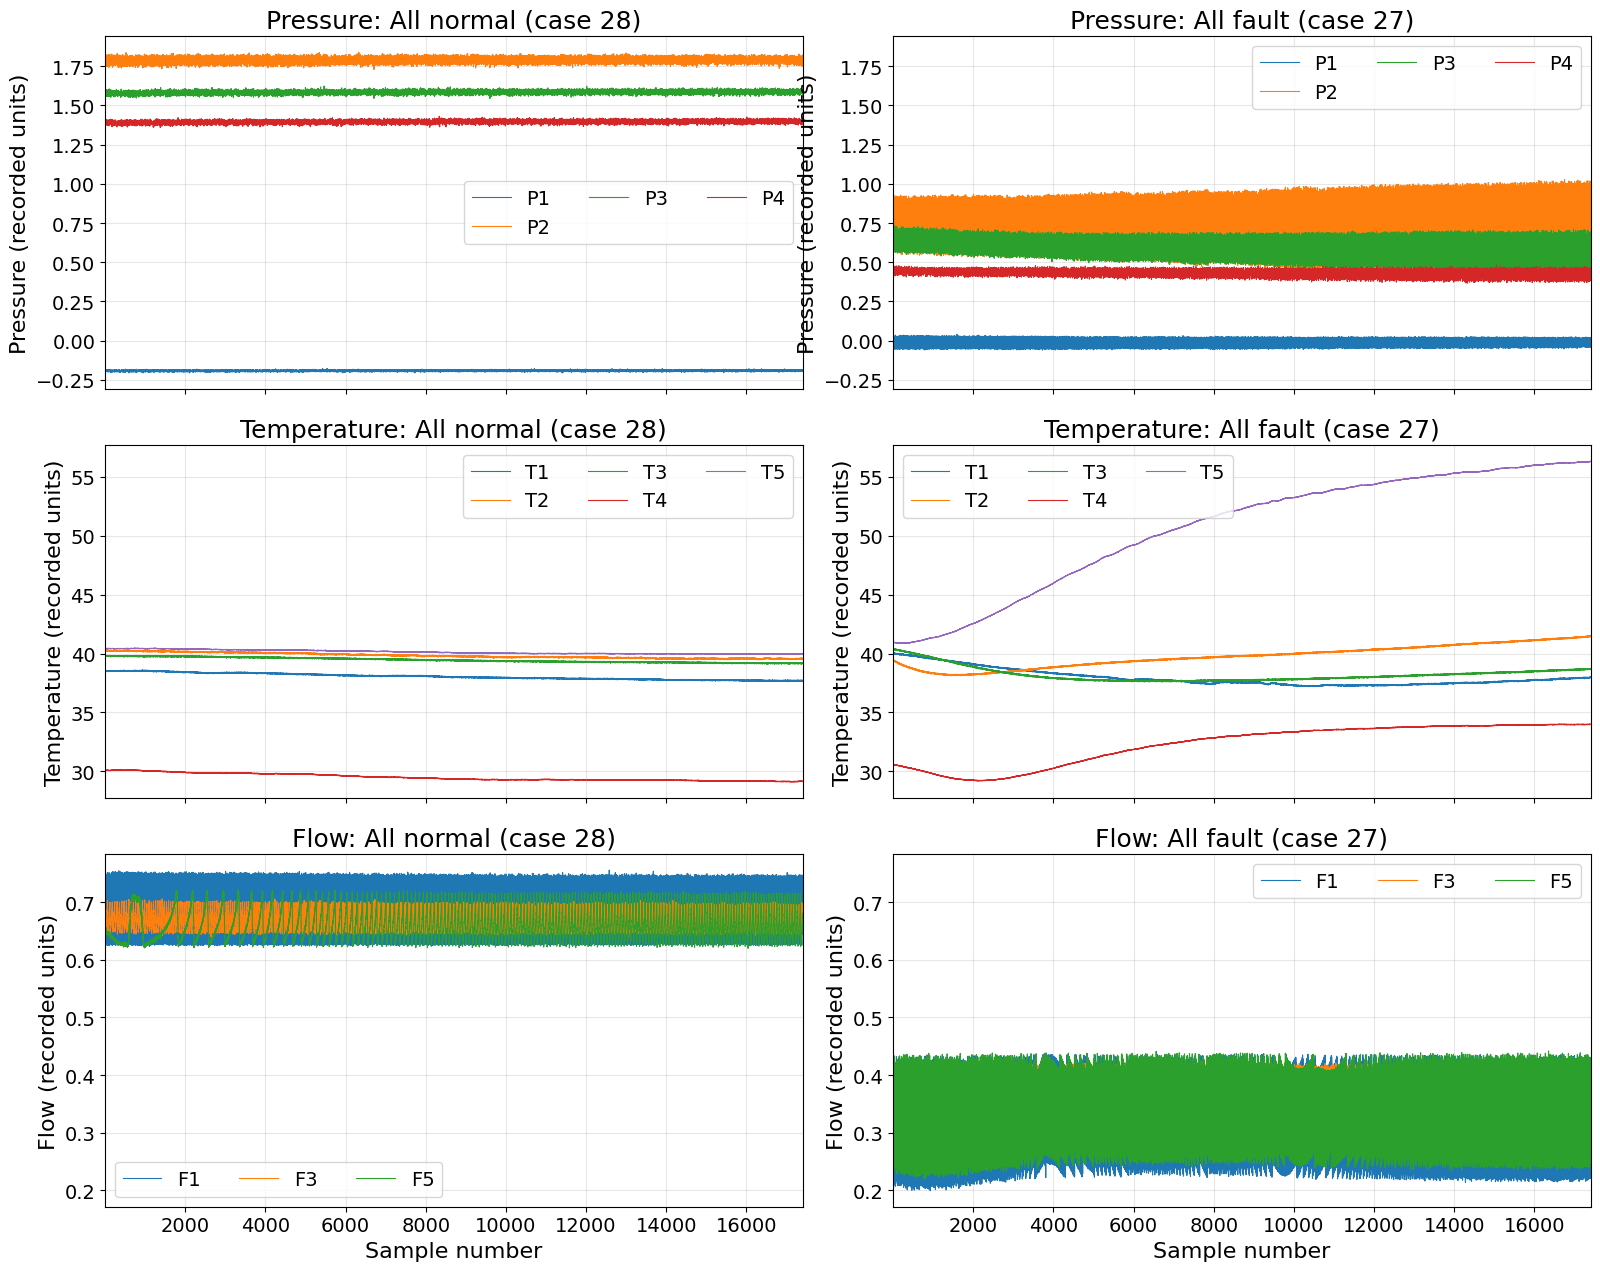

In [ ]:
# User settings: normal and severe cases; original case order is unchanged.
NORMAL_CASE_ID = 28
FAULT_CASE_ID = 27

# Verify the selected conditions before comparing the raw sensor signals.
normal_idx, fault_idx = NORMAL_CASE_ID - 1, FAULT_CASE_ID - 1
assert np.all(condition_code[normal_idx] == NORMAL_LEVEL), 'Expected all-normal condition.'
assert np.all(condition_code[fault_idx] == 2), 'Expected all-fault condition.'

# Group only the 12 component-condition channels; exclude Pb, Tb and Vib.
sensor_groups = {
    'Pressure': [0, 1, 2, 3],
    'Temperature': [5, 6, 7, 8, 9],
    'Flow': [10, 12, 13],
}
sample_number = np.arange(1, data.shape[0] + 1)
fig, axes = plt.subplots(3, 2, figsize=(16, 13), sharex=True, sharey='row')
for row, (group, channels) in enumerate(sensor_groups.items()):
    for col, (case_idx, label) in enumerate([(normal_idx, 'All normal'),
                                            (fault_idx, 'All fault')]):
        ax = axes[row, col]
        for color_idx, channel in enumerate(channels):
            ax.plot(sample_number, data[:, channel, case_idx],
                    color=f'C{color_idx}', linewidth=0.8, label=sensor_names[channel])
        ax.set_title(f'{group}: {label} (case {case_idx + 1})')
        ax.set_ylabel(f'{group} (recorded units)')
        ax.grid(True, alpha=0.3)
        ax.legend(ncol=3)
        ax.tick_params(labelleft=True)
    axes[row, 0].set_xlim(sample_number[0], sample_number[-1])
for ax in axes[-1]:
    ax.set_xlabel('Sample number')
plt.tight_layout(); plt.show()


## Compare bearing pressure, temperature and vibration
Compare the same all-normal/all-severe cases using three y-axes: Pb on the left (blue), Tb on the inner right (red), and Vib on the outer right (green). Each signal has the same scale in the normal and severe panels. Separate axes avoid implying that pressure, temperature and vibration share units. No filtering or normalization is applied. The Vib channel is displayed as recorded; it is not assumed to be a high-frequency raw waveform.

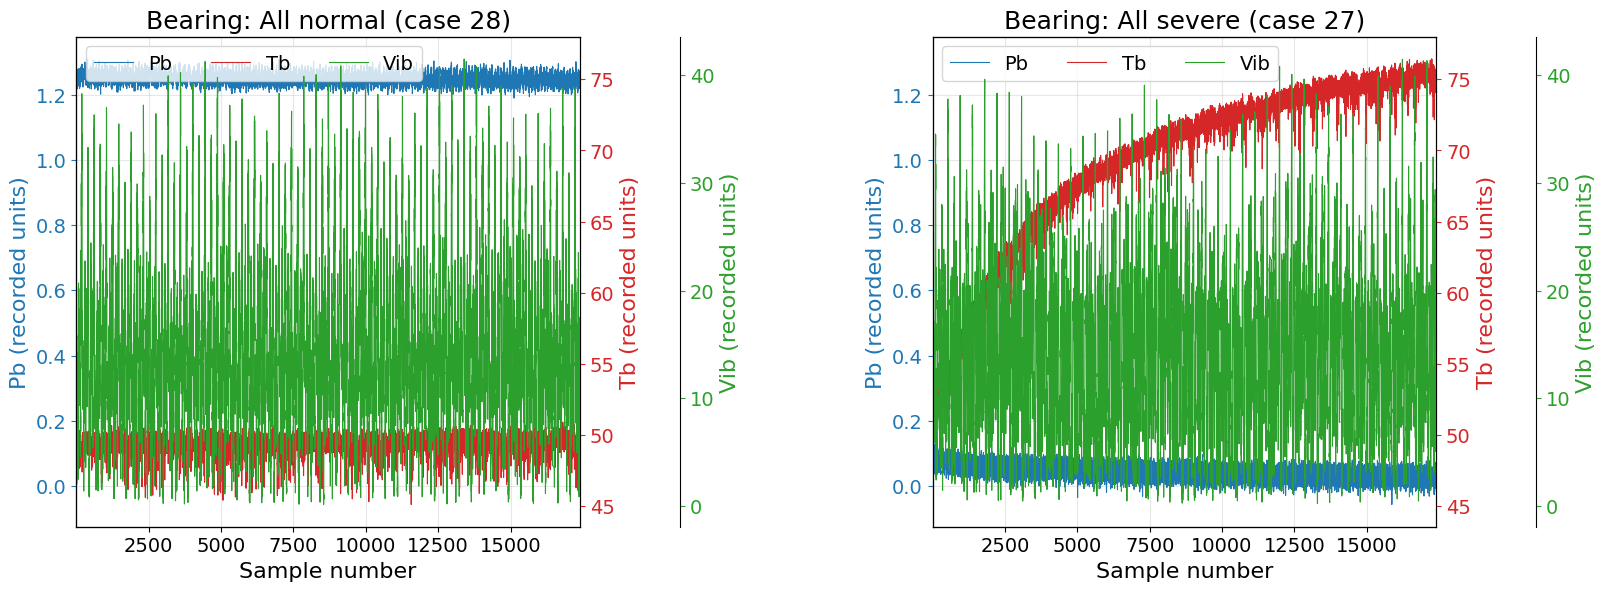

In [ ]:
# Compare the three bearing-response channels with separate colored y-axes.
# Pb uses the left axis; Tb and Vib use the inner and outer right axes.
bearing_channels = [4, 11, 14]
bearing_colors = ['tab:blue', 'tab:red', 'tab:green']
bearing_labels = ['Pb (recorded units)', 'Tb (recorded units)', 'Vib (recorded units)']

# Match each physical channel's limits between normal and severe panels.
bearing_limits = []
for channel in bearing_channels:
    values = data[:, channel, [normal_idx, fault_idx]]
    lower, upper = float(values.min()), float(values.max())
    padding = max((upper - lower) * 0.05, 1e-6)
    bearing_limits.append((lower - padding, upper + padding))

fig_bearing, base_axes = plt.subplots(1, 2, figsize=(17, 7))
fig_bearing.subplots_adjust(left=0.07, right=0.87, bottom=0.16, top=0.86, wspace=0.70)
for base, (case_idx, label) in zip(base_axes, [(normal_idx, 'All normal'),
                                             (fault_idx, 'All severe')]):
    temperature_axis = base.twinx()
    vibration_axis = base.twinx()
    vibration_axis.spines['right'].set_position(('outward', 72))
    lines = []
    for axis, channel, color, axis_label, limits in zip(
            [base, temperature_axis, vibration_axis], bearing_channels,
            bearing_colors, bearing_labels, bearing_limits):
        line, = axis.plot(sample_number, data[:, channel, case_idx],
                          color=color, linewidth=0.8, label=sensor_names[channel])
        lines.append(line)
        axis.set_ylabel(axis_label, color=color)
        axis.tick_params(axis='y', colors=color)
        axis.set_ylim(*limits)
    base.set_xlim(sample_number[0], sample_number[-1])
    base.set_xlabel('Sample number')
    base.set_title(f'Bearing: {label} (case {case_idx + 1})')
    base.grid(True, alpha=0.3)
    base.legend(lines, [line.get_label() for line in lines], loc='upper left', ncol=3)
plt.show()


## Prepare full-record inputs
Use all complete 300-sample windows from every test. No chronological training/validation/test partition is used. Sampling frequency and sensor units remain unconfirmed. Windowing is only the feature/model input representation.

In [ ]:
# User settings: retain every complete window across the entire record.
WINDOW = 300  # Samples per window, not seconds; divisible by four for the CNN
START_SAMPLE = 0  # Include the complete recorded time range

# Windowing computes features or model inputs; it does not split time into subsets.
assert WINDOW > 0 and WINDOW % 4 == 0
assert 0 <= START_SAMPLE < data.shape[0]
n_windows = (data.shape[0] - START_SAMPLE) // WINDOW
stop_sample = START_SAMPLE + n_windows * WINDOW
X_all = data[START_SAMPLE:stop_sample].transpose(2, 0, 1).reshape(
    data.shape[2], n_windows, WINDOW, 15)
fault_cases = np.flatnonzero(np.any(condition_code != NORMAL_LEVEL, axis=1))
print('X_all:', X_all.shape, '(cases, windows, samples, sensors)')
print('Normal reference case:', normal_case + 1)
print('Normal reference windows:', n_windows)
print('Component-fault cases:', len(fault_cases))
print('Unused tail samples per case:', data.shape[0] - stop_sample)


X_all: (81, 58, 300, 15) (cases, windows, samples, sensors)
Normal reference case: 28
Normal reference windows: 58
Component-fault cases: 80
Unused tail samples per case: 0


# Mahalanobis-distance anomaly detection
Use sensor means and standard deviations: 24 component features and 6 bearing features. Estimate the reference from all normal windows, with shrinkage covariance. Calibrate the threshold on the same reference scores; this is not independent false-alarm validation.

Component: 24 features; shrinkage = 0.077
Bearing: 6 features; shrinkage = 0.321

Mahalanobis distance / Component
Normal reference tests: 1; reference windows: 58
Component-fault tests: 80; evaluated windows: 4640
Threshold: 5.429
Component fault detection rate: 1.000
Independent false-alarm rate: not evaluated

Mahalanobis distance / Bearing
Normal reference tests: 1; reference windows: 58
Component-fault tests: 80; evaluated windows: 4640
Threshold: 3.148
Bearing reference-deviation fraction under component faults: 1.000
Independent false-alarm rate: not evaluated


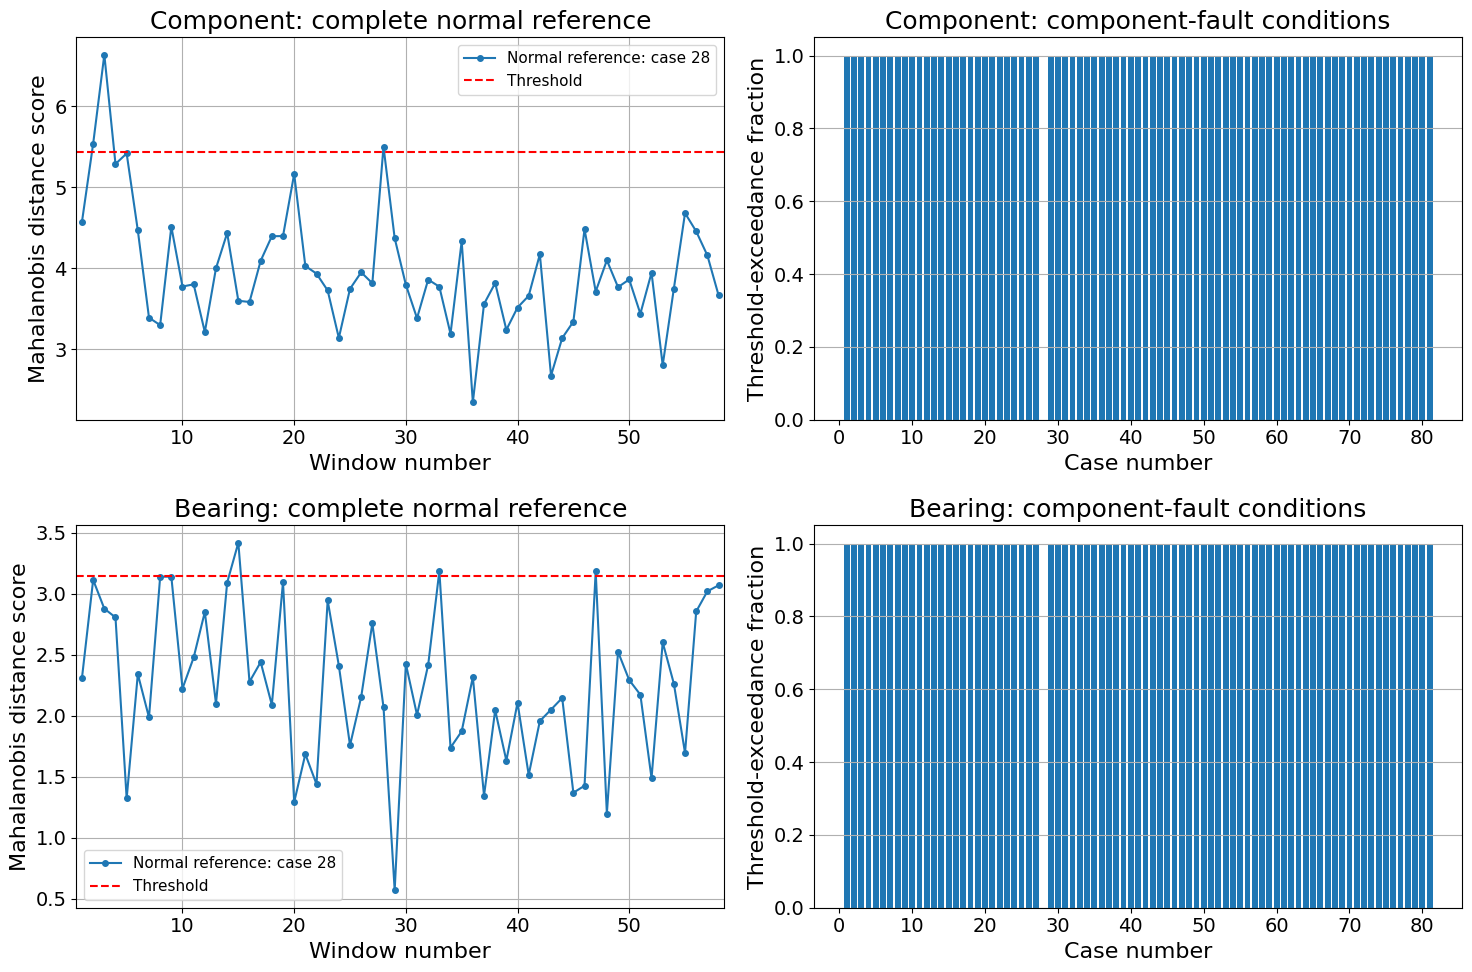

,Case,Pump,Filter blockage,Cooler blockage,Cooler,Component threshold-exceedance fraction,Bearing threshold-exceedance fraction
0,1,0,0,0,1,1.000,1.000
1,2,0,0,2,0,1.000,1.000
2,3,0,0,2,2,1.000,1.000
3,4,0,1,1,0,1.000,1.000
4,5,0,1,1,2,1.000,1.000
...,...,...,...,...,...,...,...
76,77,2,2,0,1,1.000,1.000
77,78,2,2,0,2,1.000,1.000
78,79,2,2,1,1,1.000,1.000
79,80,2,2,1,2,1.000,1.000


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.covariance import LedoitWolf

# User settings: calibrate the threshold on the complete normal reference.
md_threshold_percentile = 95
md_results = {}
for group, channels in groups.items():
    # Extract sensor means and standard deviations from every window.
    x_group = X_all[..., channels]
    features = np.concatenate([x_group.mean(axis=2), x_group.std(axis=2)], axis=-1)
    reference_features = features[normal_case]

    # Estimate scaling, mean and shrinkage covariance from the entire normal test.
    scaler = StandardScaler().fit(reference_features)
    covariance = LedoitWolf().fit(scaler.transform(reference_features))
    scaled = scaler.transform(features.reshape(-1, features.shape[-1]))
    scores = np.sqrt(np.maximum(covariance.mahalanobis(scaled), 0)).reshape(features.shape[:2])
    threshold = np.percentile(scores[normal_case], md_threshold_percentile)
    md_results[group] = dict(scores=scores, threshold=threshold, features=features,
                            scaler=scaler, covariance=covariance)
    print(f'{group}: {features.shape[-1]} features; shrinkage = {format_number(covariance.shrinkage_)}')

md_summary = show_anomaly_results(md_results, 'Mahalanobis distance')


# Autoencoder anomaly detection
Use the Chapter 4 compact CNN structure. Train on all windows from the normal record and evaluate full-record reconstruction errors. Use training-loss early stopping because no independent normal validation record is available. Thresholds are calibrated on reference reconstruction errors, not on fault data.

## Functions

In [ ]:
# Purpose: calculate the Chapter 4 reconstruction RMSE.
# Input: trained model and normalized windows (windows, samples, sensors).
# Output: one reconstruction RMSE per window.
def reconstruction_rmse(model, X):
    X_pred = model.predict(X, verbose=0)
    return np.sqrt(np.mean((X - X_pred) ** 2, axis=(1, 2)))

# Purpose: build the same compact CNN autoencoder used in Chapter 4.
# Input: window length and number of input sensors.
# Output: compiled Keras autoencoder.
def build_autoencoder(seq_len, n_channels):
    inputs = layers.Input(shape=(seq_len, n_channels), name='input')
    x = layers.Conv1D(8, 7, strides=2, padding='same', activation='relu', name='encoder_conv1')(inputs)
    x = layers.Dropout(0.2, name='encoder_dropout1')(x)
    x = layers.Conv1D(16, 7, strides=2, padding='same', activation='relu', name='latent')(x)
    x = layers.Conv1DTranspose(8, 8, strides=2, padding='same', activation='relu', name='decoder_deconv1')(x)
    x = layers.Dropout(0.2, name='decoder_dropout1')(x)
    outputs = layers.Conv1DTranspose(n_channels, 8, strides=2, padding='same', activation='linear', name='output')(x)
    model = models.Model(inputs, outputs, name='compact_cnn_autoencoder')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
    return model


## Train normal-reference models


Component: 12 sensors; 58 reference windows


Model: "compact_cnn_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 300, 12)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_conv1 (Conv1D)          │ (None, 150, 8)         │           680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout1 (Dropout)      │ (None, 150, 8)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Conv1D)                 │ (None, 75, 16)         │           912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_deconv1                 │ (None, 150, 8)         │         1,032 │
│ (Conv1DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dropout1 (Dropout)      │ (None, 150, 8)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Conv1DTranspose)        │ (None, 300, 12)        │           780 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,404 (13.30 KB)

 Trainable params: 3,404 (13.30 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 2,315 (9.04 KB)

 Trainable params: 2,315 (9.04 KB)

 Non-trainable params: 0 (0.00 B)

Independent validation/test normal records: unavailable
Epoch 1: training loss=1.056; validation loss=nan
Epoch 100: training loss=0.377; validation loss=nan
Completed epochs: 120; best epoch: 119
Best training loss: 0.359
Training time: 9.462 s


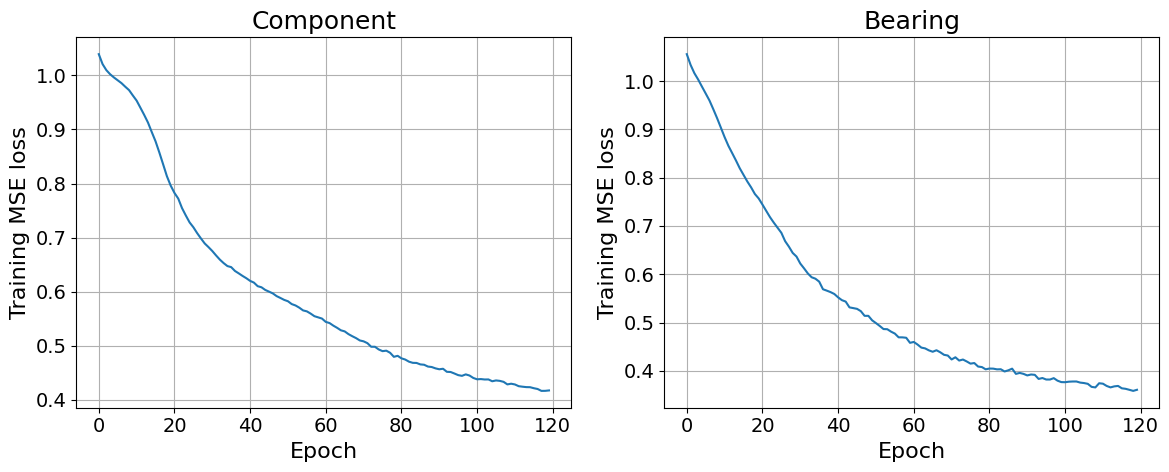

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
import time

# User settings: preserve the Chapter 4 CNN and optimizer settings.
progress_interval = 100
patience = 15
maximum_epochs = 120
batch_size = 32
ae_threshold_percentile = 95

# Train each model on windows covering the entire normal record.
results = {}
for group, channels in groups.items():
    tf.keras.utils.set_random_seed(42)
    x_group = X_all[..., channels]
    reference = x_group[normal_case]
    mean = reference.mean(axis=(0, 1), keepdims=True)
    std = reference.std(axis=(0, 1), keepdims=True)
    std = np.where(std < 1e-8, 1.0, std)
    reference_norm = (reference - mean) / std
    model = build_autoencoder(WINDOW, len(channels))
    print(f'\n{group}: {len(channels)} sensors; {len(reference)} reference windows')
    model.summary()
    print('Independent validation/test normal records: unavailable')

    # Monitor training loss; do not reserve the end of the normal time series.
    started = time.perf_counter()
    history = model.fit(reference_norm, reference_norm,
        epochs=maximum_epochs, batch_size=batch_size,
        callbacks=[EarlyStopping(monitor='loss', patience=patience, restore_best_weights=True),
                   training_progress(progress_interval)], verbose=0)
    report_training(history, started)

    # Freeze the normal model and apply it to every complete test record.
    scores = np.stack([reconstruction_rmse(model, (case - mean) / std) for case in x_group])
    threshold = np.percentile(scores[normal_case], ae_threshold_percentile)
    results[group] = dict(model=model, mean=mean, std=std, history=history.history,
                         threshold=threshold, scores=scores, channels=channels)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (group, result) in zip(axes, results.items()):
    ax.plot(result['history']['loss'])
    ax.set(title=group, xlabel='Epoch', ylabel='Training MSE loss')
    ax.grid(True)
plt.tight_layout(); plt.show()


## Evaluate component-fault conditions


Reconstruction RMSE / Component
Normal reference tests: 1; reference windows: 58
Component-fault tests: 80; evaluated windows: 4640
Threshold: 0.604
Component fault detection rate: 1.000
Independent false-alarm rate: not evaluated

Reconstruction RMSE / Bearing
Normal reference tests: 1; reference windows: 58
Component-fault tests: 80; evaluated windows: 4640
Threshold: 0.554
Bearing reference-deviation fraction under component faults: 1.000
Independent false-alarm rate: not evaluated


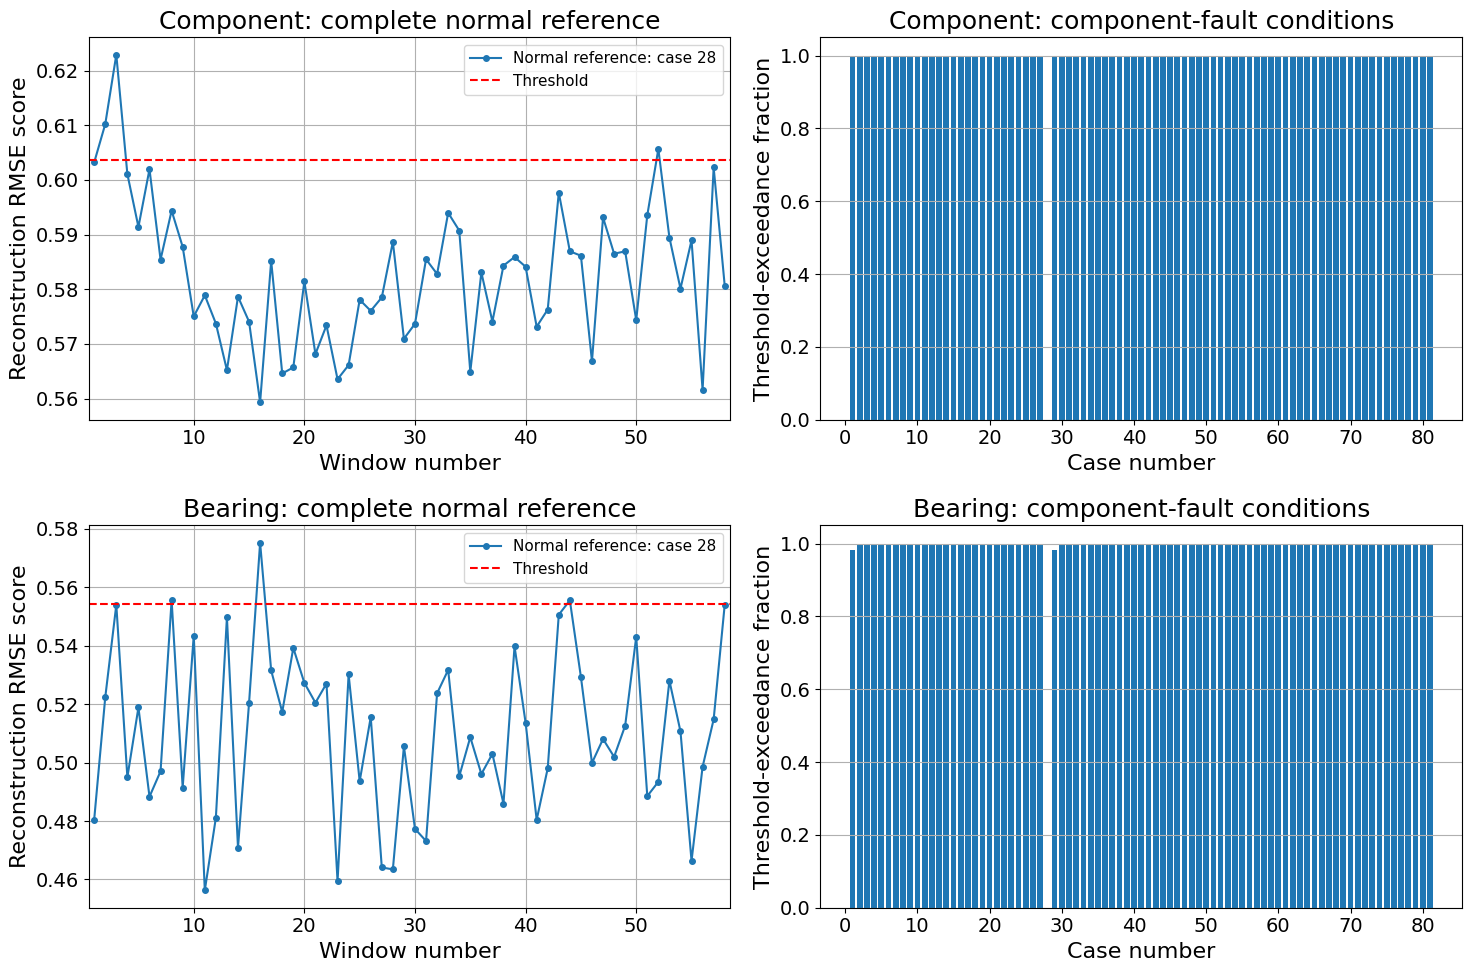

,Case,Pump,Filter blockage,Cooler blockage,Cooler,Component threshold-exceedance fraction,Bearing threshold-exceedance fraction
0,1,0,0,0,1,1.000,0.983
1,2,0,0,2,0,1.000,1.000
2,3,0,0,2,2,1.000,1.000
3,4,0,1,1,0,1.000,1.000
4,5,0,1,1,2,1.000,1.000
...,...,...,...,...,...,...,...
76,77,2,2,0,1,1.000,1.000
77,78,2,2,0,2,1.000,1.000
78,79,2,2,1,1,1.000,1.000
79,80,2,2,1,2,1.000,1.000


In [ ]:
ae_summary = show_anomaly_results(results, 'Reconstruction RMSE')

## Compare complete original and reconstructed signals

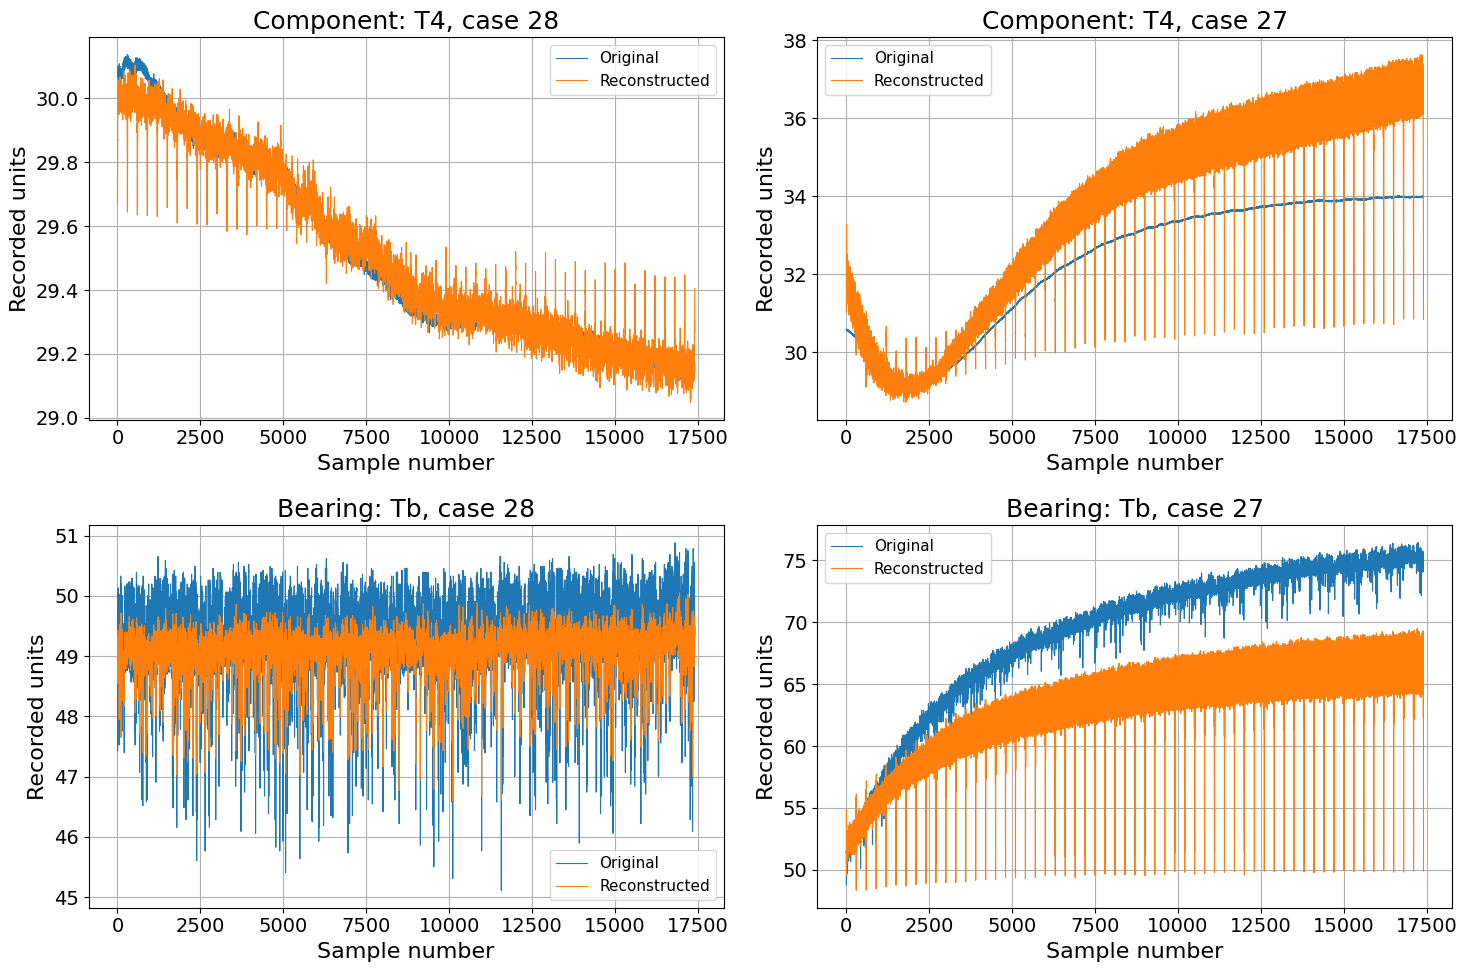

In [ ]:
# User settings: compare the complete normal and all-severe records.
DISPLAY_FAULT_CASE_ID = 27
representative_sensors = {'Component': 'T4', 'Bearing': 'Tb'}
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for row, (group, result) in enumerate(results.items()):
    local_channel = [sensor_names[i] for i in result['channels']].index(representative_sensors[group])
    for col, case_idx in enumerate([normal_case, DISPLAY_FAULT_CASE_ID - 1]):
        original = X_all[case_idx][..., result['channels']]
        normalized = (original - result['mean']) / result['std']
        reconstructed = result['model'].predict(normalized, verbose=0)
        reconstructed = reconstructed * result['std'] + result['mean']
        sample_number = np.arange(START_SAMPLE + 1, stop_sample + 1)
        ax = axes[row, col]
        ax.plot(sample_number, original[..., local_channel].ravel(), label='Original', linewidth=0.8)
        ax.plot(sample_number, reconstructed[..., local_channel].ravel(), label='Reconstructed', linewidth=0.8)
        ax.set(title=f"{group}: {representative_sensors[group]}, case {case_idx + 1}",
               xlabel='Sample number', ylabel='Recorded units')
        ax.legend(fontsize=11); ax.grid(True)
plt.tight_layout(); plt.show()


## Inspect window scores and sensor errors

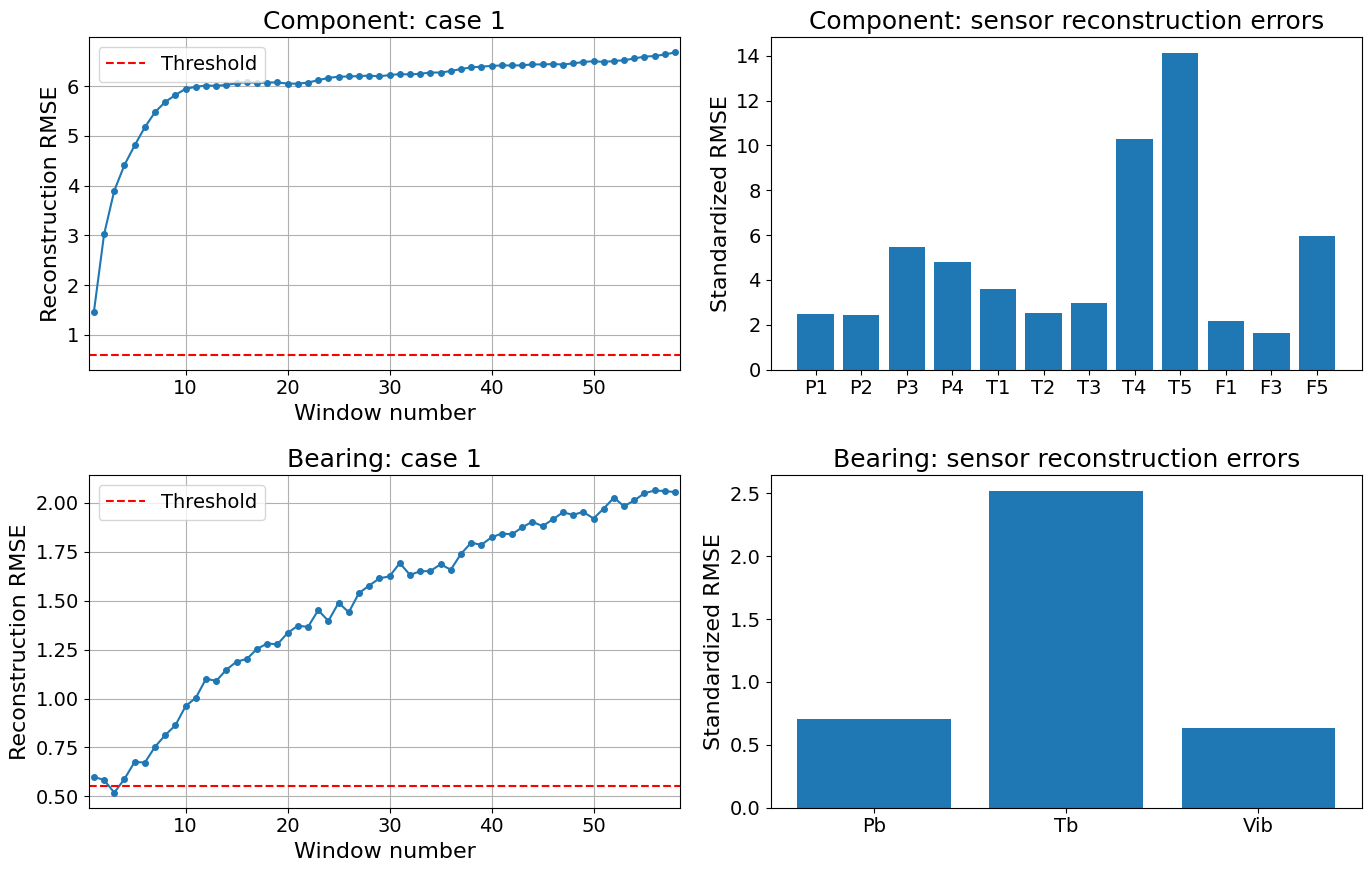

In [ ]:
# User settings: select the test to inspect.
CASE_ID = 1  # 1-based case number
# Display every window, including the entire normal reference.
case_idx = CASE_ID - 1
assert 0 <= case_idx < data.shape[2]
window_ids = np.arange(n_windows)
window_numbers = window_ids + 1
# Display window scores and standardized sensor reconstruction errors.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, (group, r) in enumerate(results.items()):
    scores = r['scores'][case_idx, window_ids]
    axes[row, 0].plot(window_numbers, scores, marker='o', markersize=4, linestyle='-')
    axes[row, 0].axhline(r['threshold'], color='r', linestyle='--', label='Threshold')
    axes[row, 0].set(title=f'{group}: case {CASE_ID}', xlabel='Window number', ylabel='Reconstruction RMSE')
    axes[row, 0].set_xlim(0.5, n_windows + 0.5)
    axes[row, 0].legend(); axes[row, 0].grid(True)
    x = X_all[case_idx, window_ids][..., r['channels']]
    xn = (x - r['mean']) / r['std']
    xp = r['model'].predict(xn, verbose=0)
    channel_rmse = np.sqrt(np.mean((xn - xp) ** 2, axis=(0, 1)))
    axes[row, 1].bar([sensor_names[i] for i in r['channels']], channel_rmse)
    axes[row, 1].set(title=f'{group}: sensor reconstruction errors', ylabel='Standardized RMSE')
plt.tight_layout(); plt.show()


# Binary component diagnosis using the ZeMA ANN
Use the shared `FEATURE_MODE` option in the next preparation cell: **24** = 12 sensor means/STDs; **32** = add four difference-signal means/STDs; **44** = also add six physical-proxy means/STDs. Default: 44. Input dimension changes automatically; the 10-ReLU hidden layer and four Sigmoid outputs remain fixed.

Output order: Pump, Filter blockage, Cooler blockage, Cooler. Stored code 0 is normal; codes 1 and 2 are merged into fault. Preserve the existing case-level split and train-only scaling. Set FEATURE_MODE once and execute feature preparation, then continue through binary training/evaluation and severity preparation/training/evaluation in order. Severity diagnosis then uses that same prepared FEATURE_MODE; there is no separate option. Same-runtime comparison tables retain results for all modes. More features do not guarantee better performance.

Run settings/utilities and data/window preparation first. No anomaly-detector training is required. Six physical proxies are candidate physical relationships, not calibrated powers, efficiencies or dimensionless quantities. F1 is used for pump flow and F3 for filter/cooler flow; denominator floors use training data only.

## Prepare common feature options, labels and case-level splits

In [59]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# User settings: one feature option shared by binary and severity ANN diagnosis.
FEATURE_MODE = 44  # 24: sensors; 32: sensors + differences; 44: also six physical proxies
flow_floor_fraction = 0.01
test_ratio = 0.30
ann_validation_ratio = 0.20
random_state = 42
assert FEATURE_MODE in (24, 32, 44)

# Preserve the original parent-test split for all three representations.
binary_labels_case = (condition_code != NORMAL_LEVEL).astype(int)
case_ids = np.arange(len(condition_code))
development_cases, binary_test_cases = train_test_split(
    case_ids, test_size=test_ratio, random_state=random_state,
    stratify=np.maximum(binary_labels_case.sum(axis=1), 1))
binary_train_cases, binary_val_cases = train_test_split(
    development_cases, test_size=ann_validation_ratio, random_state=random_state,
    stratify=np.maximum(binary_labels_case[development_cases].sum(axis=1), 1))
assert not (set(binary_train_cases) & set(binary_val_cases)
            or set(binary_train_cases) & set(binary_test_cases)
            or set(binary_val_cases) & set(binary_test_cases))

# Build all three variants once; the ratio floor is estimated from training cases only.
diagnostic_feature_sets, diagnostic_feature_names, flow_floor, floor_fraction = extract_tgls_feature_sets(
    X_all, component_idx, sensor_names, binary_train_cases, flow_floor_fraction)
binary_features = diagnostic_feature_sets[FEATURE_MODE]
feature_names_binary = diagnostic_feature_names[FEATURE_MODE]
n_binary_features = binary_features.shape[-1]
prepared_feature_mode = FEATURE_MODE

# Keep the 44-feature BN candidate pool independent of the ANN feature option.
physics_features = diagnostic_feature_sets[44]
physics_feature_names = diagnostic_feature_names[44]
sensor_features = diagnostic_feature_sets[24]
physical_features = diagnostic_feature_sets[32][..., 24:]
print('Feature mode:', FEATURE_MODE, '; feature matrix:', binary_features.shape)
print('Flow denominator floor:', format_number(flow_floor))
print('Fraction of samples below floor:', format_number(floor_fraction))
display(pd.DataFrame({'Feature': feature_names_binary}))

# Flatten windows after splitting complete tests, then fit scaling on training data only.
x_binary_train_raw = binary_features[binary_train_cases].reshape(-1, n_binary_features)
x_binary_val_raw = binary_features[binary_val_cases].reshape(-1, n_binary_features)
x_binary_test_raw = binary_features[binary_test_cases].reshape(-1, n_binary_features)
y_binary_train = np.repeat(binary_labels_case[binary_train_cases], n_windows, axis=0)
y_binary_val = np.repeat(binary_labels_case[binary_val_cases], n_windows, axis=0)
y_binary_test = np.repeat(binary_labels_case[binary_test_cases], n_windows, axis=0)
scaler_binary = StandardScaler().fit(x_binary_train_raw)
x_binary_train = scaler_binary.transform(x_binary_train_raw).astype(np.float32)
x_binary_val = scaler_binary.transform(x_binary_val_raw).astype(np.float32)
x_binary_test = scaler_binary.transform(x_binary_test_raw).astype(np.float32)
for name, ids, labels in [('Training', binary_train_cases, y_binary_train),
                         ('Validation', binary_val_cases, y_binary_val),
                         ('Test', binary_test_cases, y_binary_test)]:
    assert all(len(np.unique(labels[:, j])) == 2 for j in range(4))
    print(f'{name}: {len(ids)} cases; {len(labels)} windows')
    print('Case IDs (1-based):', np.sort(ids + 1))
    display(pd.DataFrame({'Component': fault_names,
        'Normal cases': (binary_labels_case[ids] == 0).sum(axis=0),
        'Fault cases': (binary_labels_case[ids] == 1).sum(axis=0)}))


Feature mode: 44 ; feature matrix: (81, 58, 44)
Flow denominator floor: 0.005
Fraction of samples below floor: 0.000


,Feature
0,P1-Mean
1,P2-Mean
2,P3-Mean
3,P4-Mean
4,T1-Mean
5,T2-Mean
6,T3-Mean
7,T4-Mean
8,T5-Mean
9,F1-Mean


Training: 44 cases; 2552 windows
Case IDs (1-based): [ 1  2  4  5  7  9 11 16 18 19 20 21 22 24 27 29 31 33 34 37 38 40 41 43
 45 46 48 49 53 54 55 57 58 59 61 62 63 65 66 68 72 73 80 81]


,Component,Normal cases,Fault cases
0,Pump,16,28
1,Filter blockage,15,29
2,Cooler blockage,13,31
3,Cooler,14,30


Validation: 12 cases; 696 windows
Case IDs (1-based): [ 3  6 12 15 35 39 47 60 64 71 74 76]


,Component,Normal cases,Fault cases
0,Pump,4,8
1,Filter blockage,4,8
2,Cooler blockage,4,8
3,Cooler,4,8


Test: 25 cases; 1450 windows
Case IDs (1-based): [ 8 10 13 14 17 23 25 26 28 30 32 36 42 44 50 51 52 56 67 69 70 75 77 78
 79]


,Component,Normal cases,Fault cases
0,Pump,7,18
1,Filter blockage,8,17
2,Cooler blockage,10,15
3,Cooler,9,16


## Train the four-output ANN

Model structure


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 10)             │           450 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 4)              │            44 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 494 (1.93 KB)

 Trainable params: 494 (1.93 KB)

 Non-trainable params: 0 (0.00 B)

Parameters: 494 total; 494 trainable
Training samples: 2,552
Validation samples: 696
Training input shapes: [(2552, 44)]
Validation input shapes: [(696, 44)]
Test samples: 1,450
Test input shapes: [(1450, 44)]
Epoch 1: training loss=0.261; validation loss=0.213
Completed epochs: 37; best epoch: 7
Best training loss: 0.016
Best validation loss: 0.090
Training time: 34.23 s


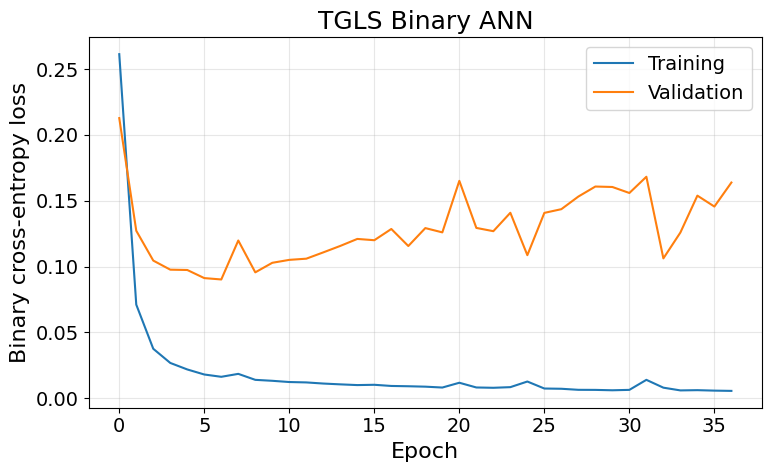

In [60]:
import time
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

# User settings: preserve the Chapter 5 ZeMA binary ANN architecture and training settings.
hidden_neurons = 10
learning_rate = 0.01
maximum_epochs = 1000
batch_size = 32
patience = 30
progress_interval = 100

binary_trained_mode = int(FEATURE_MODE)
assert prepared_feature_mode == FEATURE_MODE
tf.keras.utils.set_random_seed(random_state)
binary_model = models.Sequential([
    layers.Input(shape=(x_binary_train.shape[1],)),
    layers.Dense(hidden_neurons, activation='relu'),
    layers.Dense(4, activation='sigmoid')])
binary_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                     loss='binary_crossentropy', metrics=['binary_accuracy'])
show_model_info(binary_model, x_binary_train, x_binary_val, x_binary_test)
training_started = time.perf_counter()
binary_history = binary_model.fit(x_binary_train, y_binary_train,
    validation_data=(x_binary_val, y_binary_val), epochs=maximum_epochs, batch_size=batch_size,
    callbacks=[EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True),
               training_progress(progress_interval)], verbose=0)
report_training(binary_history, training_started)

# Plot losses; independent test labels never select the stopping epoch.
plt.figure(figsize=(8, 5))
plt.plot(binary_history.history['loss'], label='Training')
plt.plot(binary_history.history['val_loss'], label='Validation')
plt.xlabel('Epoch'); plt.ylabel('Binary cross-entropy loss')
plt.title('TGLS Binary ANN'); plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


## Evaluate held-out tests


Window-level evaluation: 1450 observations
Average label accuracy: 0.975
Exact four-component accuracy: 0.902


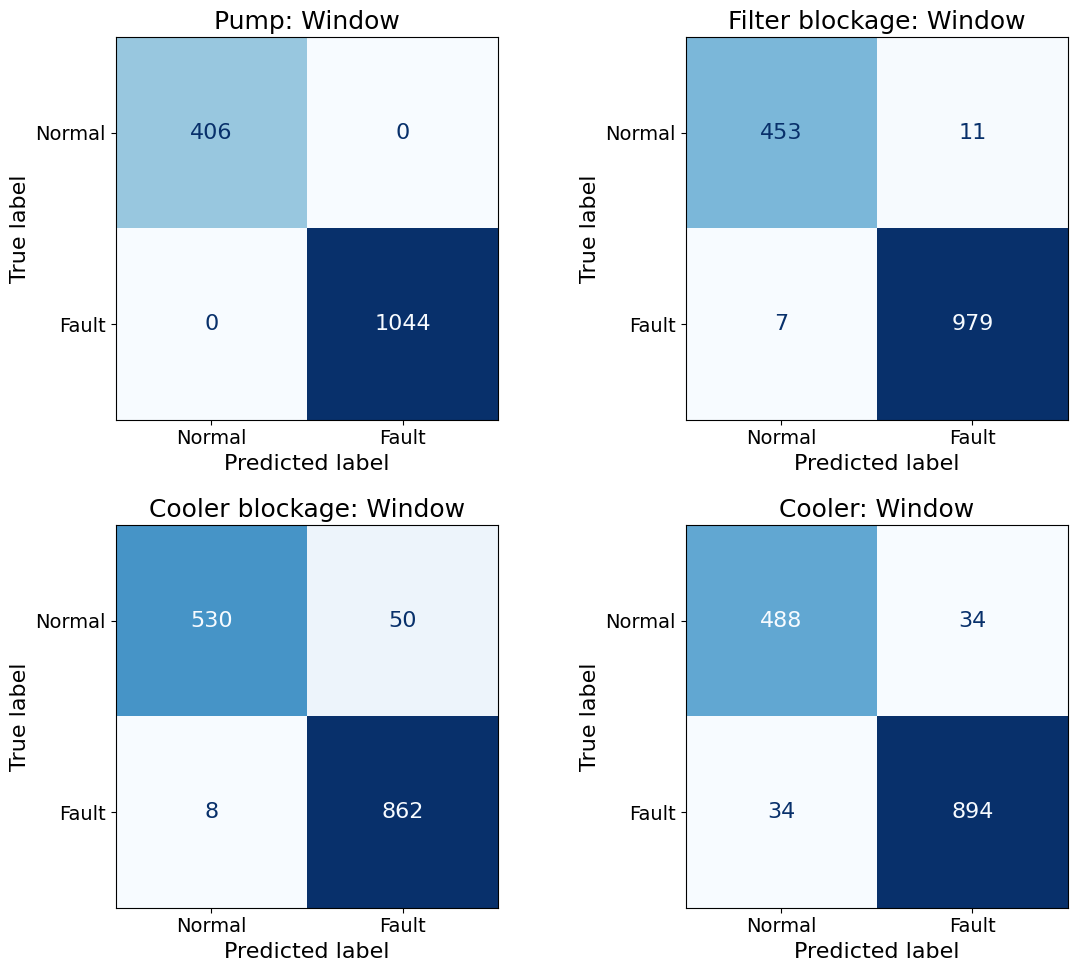


Case-level evaluation: 25 observations
Average label accuracy: 0.990
Exact four-component accuracy: 0.960


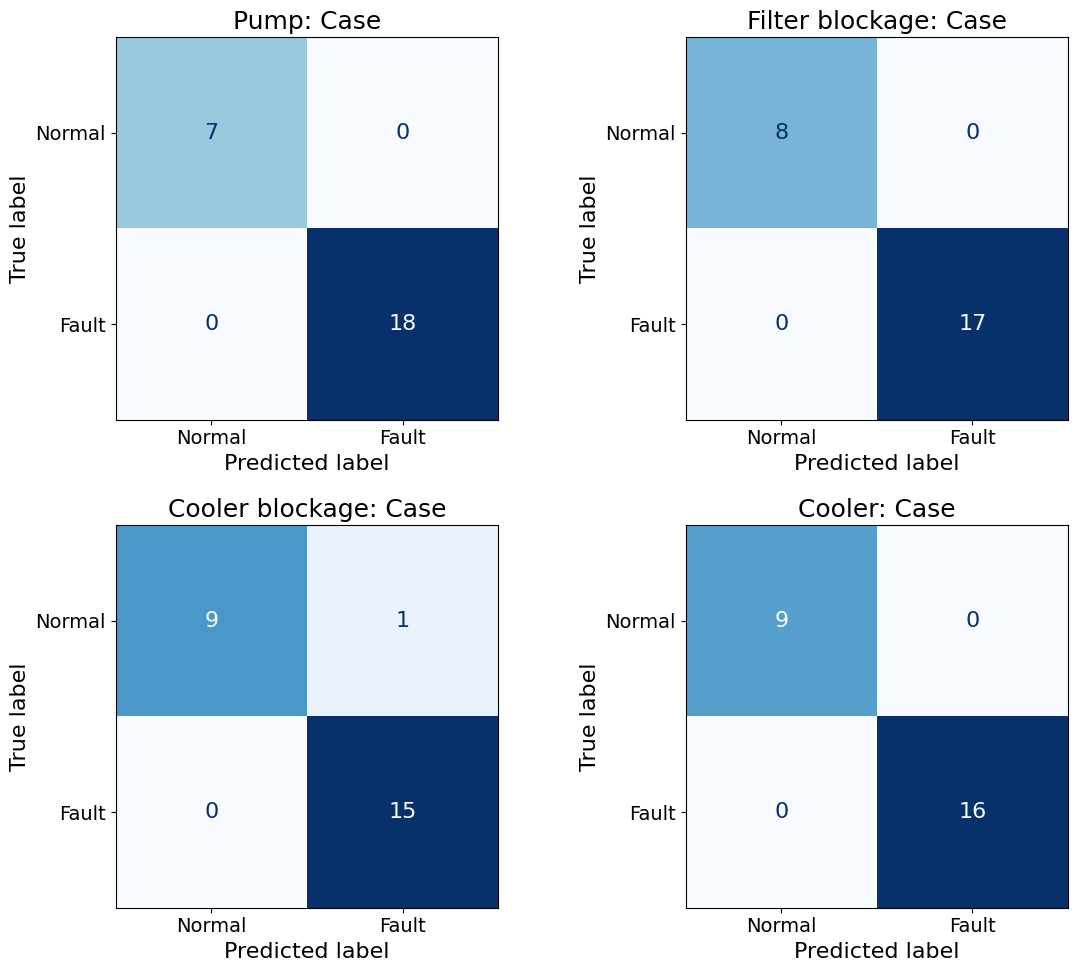

,Level,Component,Accuracy,Balanced_accuracy,False_alarm_rate,Fault_detection_rate
0,Window,Pump,1.000,1.000,0.000,1.000
1,Window,Filter blockage,0.988,0.985,0.024,0.993
2,Window,Cooler blockage,0.960,0.952,0.086,0.991
3,Window,Cooler,0.953,0.949,0.065,0.963
4,Case,Pump,1.000,1.000,0.000,1.000
5,Case,Filter blockage,1.000,1.000,0.000,1.000
6,Case,Cooler blockage,0.960,0.950,0.100,1.000
7,Case,Cooler,1.000,1.000,0.000,1.000


,Case,Pump,Filter blockage,Cooler blockage,Cooler,Pump binary truth,Pump fault probability,Pump predicted fault,Filter blockage binary truth,Filter blockage fault probability,Filter blockage predicted fault,Cooler blockage binary truth,Cooler blockage fault probability,Cooler blockage predicted fault,Cooler binary truth,Cooler fault probability,Cooler predicted fault
4,8,0,2,0,1,0,2.084e-04,0,1,1.000,1,0,1.334e-04,0,1,0.981,1
2,10,1,0,0,0,1,1.000,1,0,6.799e-07,0,0,5.986e-04,0,0,0.015,0
3,13,1,1,0,0,1,0.998,1,1,0.955,1,0,8.979e-06,0,0,0.027,0
16,14,1,1,1,1,1,1.000,1,1,0.979,1,1,0.858,1,1,0.966,1
17,17,1,2,1,1,1,1.000,1,1,1.000,1,1,0.969,1,1,0.992,1
13,23,2,1,0,2,1,1.000,1,1,0.841,1,0,0.002,0,1,0.961,1
7,25,2,2,1,0,1,0.998,1,1,0.999,1,1,0.965,1,0,0.381,0
12,26,2,2,2,1,1,1.000,1,1,0.999,1,1,1.000,1,1,0.773,1
23,28,0,0,0,0,0,7.755e-06,0,0,0.006,0,0,0.005,0,0,0.006,0
24,30,0,0,1,0,0,3.809e-05,0,0,0.003,0,1,1.000,1,0,0.005,0


Feature-mode comparison: held-out case-level metrics


,Feature mode,Component,Accuracy,Balanced_accuracy,False_alarm_rate,Fault_detection_rate
4,24 features,Pump,1.000,1.000,0.000,1.000
5,24 features,Filter blockage,0.760,0.724,0.375,0.824
6,24 features,Cooler blockage,0.880,0.850,0.300,1.000
7,24 features,Cooler,0.960,0.969,0.000,0.938
4,32 features,Pump,1.000,1.000,0.000,1.000
5,32 features,Filter blockage,0.920,0.908,0.125,0.941
6,32 features,Cooler blockage,0.920,0.900,0.200,1.000
7,32 features,Cooler,1.000,1.000,0.000,1.000
4,44 features,Pump,1.000,1.000,0.000,1.000
5,44 features,Filter blockage,1.000,1.000,0.000,1.000


In [61]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Evaluate only the model trained for the currently prepared feature representation.
assert binary_trained_mode == int(FEATURE_MODE) == prepared_feature_mode, 'Rerun ANN training after changing feature mode.'
assert binary_model.input_shape[-1] == x_binary_test.shape[-1]

# Evaluate held-out tests at both window and complete-test levels.
binary_test_probability = binary_model.predict(x_binary_test, verbose=0)
binary_window_pred = (binary_test_probability >= 0.5).astype(int)
binary_case_probability = binary_test_probability.reshape(len(binary_test_cases), n_windows, 4).mean(axis=1)
binary_case_pred = (binary_case_probability >= 0.5).astype(int)
binary_case_true = binary_labels_case[binary_test_cases]
binary_metric_rows = []
for level, true, pred in [('Window', y_binary_test, binary_window_pred),
                          ('Case', binary_case_true, binary_case_pred)]:
    print(f'\n{level}-level evaluation: {len(true)} observations')
    print('Average label accuracy:', format_number(np.mean(true == pred)))
    print('Exact four-component accuracy:', format_number(np.mean(np.all(true == pred, axis=1))))
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    for j, (name, ax) in enumerate(zip(fault_names, axes.ravel())):
        cm = confusion_matrix(true[:, j], pred[:, j], labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Fault']).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format='d')
        ax.set_title(f'{name}: {level}')
        tn, fp, fn, tp = cm.ravel()
        binary_metric_rows.append(dict(Level=level, Component=name,
            Accuracy=accuracy_score(true[:, j], pred[:, j]),
            Balanced_accuracy=balanced_accuracy_score(true[:, j], pred[:, j]),
            False_alarm_rate=fp / (tn + fp), Fault_detection_rate=tp / (tp + fn)))
    plt.tight_layout(); plt.show()
display(pd.DataFrame(binary_metric_rows))

# Show the true label and predicted fault probability for each held-out case.
binary_case_report = case_table.iloc[binary_test_cases].copy().reset_index(drop=True)
for j, name in enumerate(fault_names):
    binary_case_report[name + ' binary truth'] = binary_case_true[:, j]
    binary_case_report[name + ' fault probability'] = binary_case_probability[:, j]
    binary_case_report[name + ' predicted fault'] = binary_case_pred[:, j]
display(binary_case_report.sort_values('Case'))

# Cache comparable case-level metrics from both modes in the current runtime.
import hashlib
binary_comparison_key = hashlib.sha256(diagnostic_feature_sets[44].tobytes()
    + binary_labels_case.tobytes() + binary_train_cases.tobytes()
    + binary_val_cases.tobytes() + binary_test_cases.tobytes()
    + str((hidden_neurons, learning_rate, maximum_epochs, batch_size, patience, random_state)).encode()).hexdigest()
if globals().get('binary_saved_comparison_key') != binary_comparison_key:
    binary_difference_comparison = {}
    binary_saved_comparison_key = binary_comparison_key
binary_mode_name = f'{binary_trained_mode} features'
binary_case_metrics = pd.DataFrame(binary_metric_rows).query("Level == 'Case'").drop(columns='Level')
binary_difference_comparison[binary_mode_name] = binary_case_metrics.copy()
binary_comparison_table = pd.concat(binary_difference_comparison, names=['Feature mode']).reset_index(level=0)
print('Feature-mode comparison: held-out case-level metrics')
display(binary_comparison_table)


# Component severity diagnosis using the shared feature option
Continue directly from binary diagnosis using the same FEATURE_MODE already applied in common feature preparation. There is no separate severity feature setting. Run this section's preparation, training and evaluation in order; no return to binary preparation is needed while the feature mode remains unchanged.

Use the shared 24/32/44 feature representation, the same 44/12/25 case split and training-only scaling. The ANN has one 10-ReLU hidden layer and four 3-class Softmax outputs. Codes 0/1/2 mean normal/moderate/severe. Average class probabilities over 58 windows for case-level decisions.

For the next feature mode, change FEATURE_MODE in the binary section's feature preparation cell, execute that cell, and continue through binary and severity diagnosis. Both comparison tables accumulate results in the current runtime. Changing text in a cell without executing it does not update the runtime option.

## Prepare three-level component labels

In [62]:
# Reuse only the window-based features and parent-test split, not the binary ANN.
# Reuse the single feature option already applied by common preparation.
from sklearn.preprocessing import StandardScaler
assert FEATURE_MODE in (24, 32, 44)
assert FEATURE_MODE == prepared_feature_mode, 'Run the feature preparation cell after changing FEATURE_MODE.'
assert 'diagnostic_feature_sets' in globals(), 'Run the common feature preparation cell once first.'
severity_feature_mode = int(prepared_feature_mode)
severity_features = diagnostic_feature_sets[severity_feature_mode]
assert severity_features.shape == (len(condition_code), n_windows, severity_feature_mode)
severity_train_cases = binary_train_cases.copy()
severity_val_cases = binary_val_cases.copy()
severity_test_cases = binary_test_cases.copy()

# Stored codes already match the ordered classes: normal, moderate, severe.
# Stored mapping: raw 0 -> class 0, raw 1 -> class 1, raw 2 -> class 2.
severity_labels_case = condition_code.copy()
severity_names = ['Normal', 'Moderate', 'Severe']
severity_output_names = ['pump', 'filter_blockage', 'cooler_blockage', 'cooler']
# Fit a new scaler using the training cases and the selected feature representation only.
severity_raw_train = severity_features[severity_train_cases].reshape(-1, severity_feature_mode)
severity_raw_val = severity_features[severity_val_cases].reshape(-1, severity_feature_mode)
severity_raw_test = severity_features[severity_test_cases].reshape(-1, severity_feature_mode)
scaler_severity = StandardScaler().fit(severity_raw_train)
x_severity_train = scaler_severity.transform(severity_raw_train).astype(np.float32)
x_severity_val = scaler_severity.transform(severity_raw_val).astype(np.float32)
x_severity_test = scaler_severity.transform(severity_raw_test).astype(np.float32)
print(f'Shared FEATURE_MODE = {severity_feature_mode}; actual input dimension = {x_severity_train.shape[1]}')
y_severity_train = np.repeat(severity_labels_case[severity_train_cases], n_windows, axis=0)
y_severity_val = np.repeat(severity_labels_case[severity_val_cases], n_windows, axis=0)
y_severity_test = np.repeat(severity_labels_case[severity_test_cases], n_windows, axis=0)

# Verify representation of all severity levels in every subset.
for name, ids in [('Training', severity_train_cases), ('Validation', severity_val_cases),
                  ('Test', severity_test_cases)]:
    print(f'{name}: {len(ids)} cases; {len(ids) * n_windows} windows')
    counts = []
    for j, component in enumerate(fault_names):
        values = severity_labels_case[ids, j]
        assert len(np.unique(values)) == 3, f'{name}: missing severity for {component}'
        counts.append(dict(Component=component, Normal=int(np.sum(values == 0)),
                           Moderate=int(np.sum(values == 1)), Severe=int(np.sum(values == 2))))
    display(pd.DataFrame(counts))


Shared FEATURE_MODE = 44; actual input dimension = 44
Training: 44 cases; 2552 windows


,Component,Normal,Moderate,Severe
0,Pump,16,15,13
1,Filter blockage,15,13,16
2,Cooler blockage,13,18,13
3,Cooler,14,14,16


Validation: 12 cases; 696 windows


,Component,Normal,Moderate,Severe
0,Pump,4,4,4
1,Filter blockage,4,6,2
2,Cooler blockage,4,2,6
3,Cooler,4,4,4


Test: 25 cases; 1450 windows


,Component,Normal,Moderate,Severe
0,Pump,7,8,10
1,Filter blockage,8,8,9
2,Cooler blockage,10,7,8
3,Cooler,9,9,7


## Train the four-output severity ANN

Training severity model with 44 features
Model structure


Model: "tgls_severity_ann"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ features            │ (None, 44)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hidden (Dense)      │ (None, 10)        │        450 │ features[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cooler (Dense)      │ (None, 3)         │         33 │ hidden[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cooler_blockage     │ (None, 3)         │         33 │ hidden[0][0]      │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ filter_blockage     │ (None, 3)         │         33 │ hidden[0][0]      │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pump (Dense)        │ (None, 3)         │         33 │ hidden[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 582 (2.27 KB)

 Trainable params: 582 (2.27 KB)

 Non-trainable params: 0 (0.00 B)

Parameters: 582 total; 582 trainable
Training samples: 2,552
Validation samples: 696
Training input shapes: [(2552, 44)]
Validation input shapes: [(696, 44)]
Test samples: 1,450
Test input shapes: [(1450, 44)]
Epoch 1: training loss=2.266; validation loss=3.096
Completed epochs: 37; best epoch: 7
Best training loss: 0.159
Best validation loss: 1.556
Training time: 18.80 s


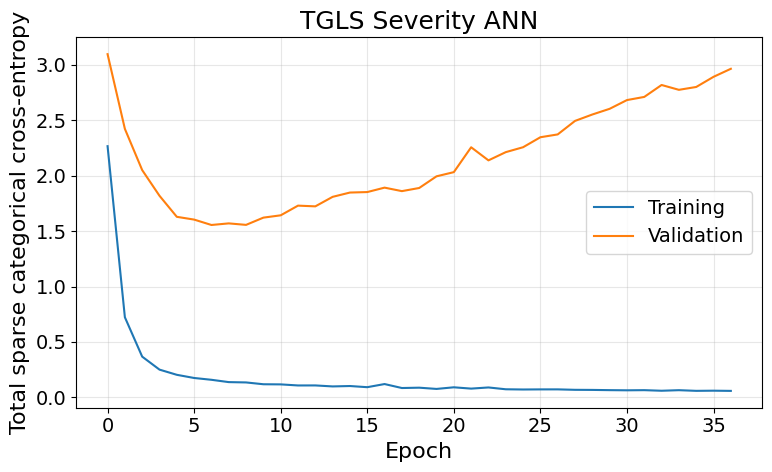

In [63]:
import time
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

# User settings: retain the binary ANN hidden width and training controls.
hidden_neurons = 10
learning_rate = 0.01
maximum_epochs = 1000
batch_size = 32
patience = 30
progress_interval = 100
random_state = 42

assert severity_feature_mode == FEATURE_MODE == prepared_feature_mode
severity_trained_mode = int(x_severity_train.shape[1])
assert severity_trained_mode == FEATURE_MODE == prepared_feature_mode
print(f'Training severity model with {severity_trained_mode} features')
tf.keras.utils.set_random_seed(random_state)
severity_input = layers.Input(shape=(x_severity_train.shape[1],), name='features')
severity_hidden = layers.Dense(hidden_neurons, activation='relu', name='hidden')(severity_input)
severity_outputs = {name: layers.Dense(3, activation='softmax', name=name)(severity_hidden)
                    for name in severity_output_names}
severity_model = models.Model(severity_input, severity_outputs, name='tgls_severity_ann')
severity_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
    loss={name: 'sparse_categorical_crossentropy' for name in severity_output_names},
    metrics={name: ['accuracy'] for name in severity_output_names})
severity_train_targets = {name: y_severity_train[:, j] for j, name in enumerate(severity_output_names)}
severity_val_targets = {name: y_severity_val[:, j] for j, name in enumerate(severity_output_names)}
show_model_info(severity_model, x_severity_train, x_severity_val, x_severity_test)
training_started = time.perf_counter()
severity_history = severity_model.fit(x_severity_train, severity_train_targets,
    validation_data=(x_severity_val, severity_val_targets),
    epochs=maximum_epochs, batch_size=batch_size,
    callbacks=[EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True),
               training_progress(progress_interval)], verbose=0)
report_training(severity_history, training_started)

# Display total loss across the four component-specific classification outputs.
plt.figure(figsize=(8, 5))
plt.plot(severity_history.history['loss'], label='Training')
plt.plot(severity_history.history['val_loss'], label='Validation')
plt.xlabel('Epoch'); plt.ylabel('Total sparse categorical cross-entropy')
plt.title('TGLS Severity ANN'); plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


## Evaluate severity by window and case

Evaluating severity model with 44 features

Window-level evaluation: 1450 observations
Average component severity accuracy: 0.886
Exact four-component severity accuracy: 0.555


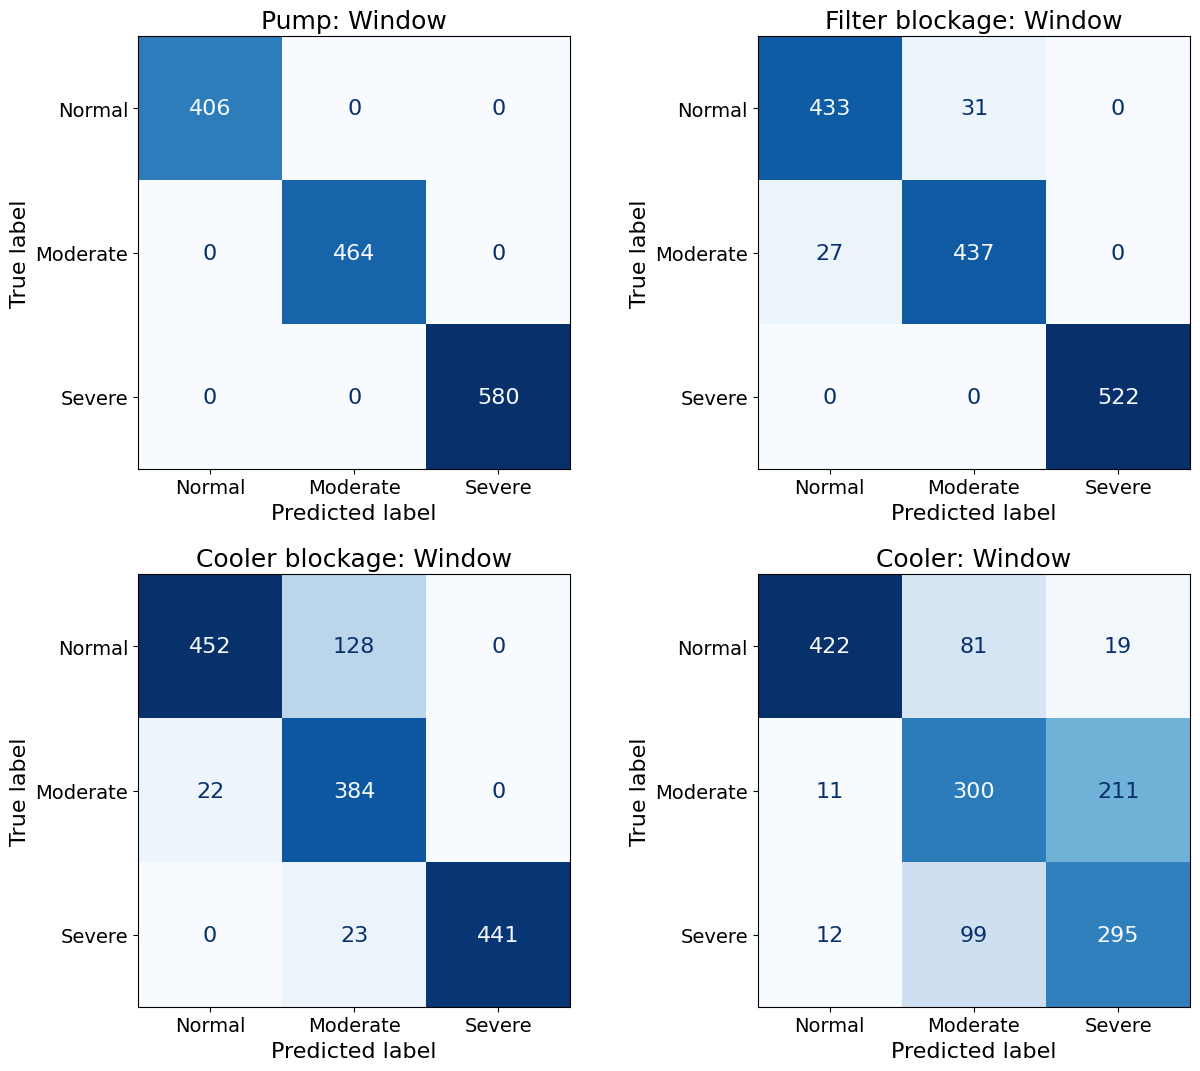


Case-level evaluation: 25 observations
Average component severity accuracy: 0.890
Exact four-component severity accuracy: 0.600


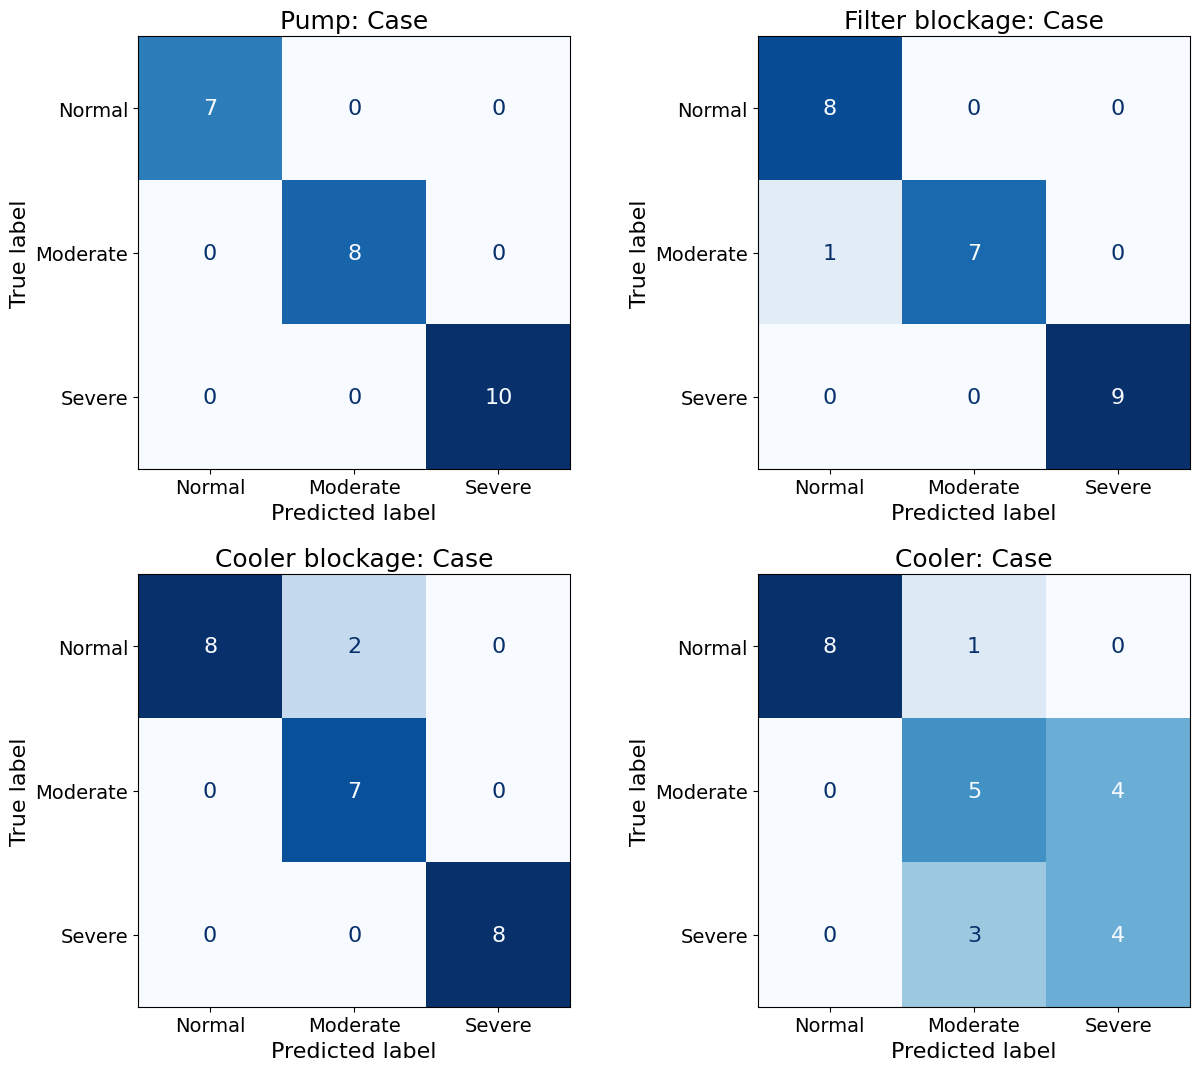

,Level,Component,Accuracy,Balanced_accuracy
0,Window,Pump,1.000,1.000
1,Window,Filter blockage,0.960,0.958
2,Window,Cooler blockage,0.881,0.892
3,Window,Cooler,0.701,0.703
4,Case,Pump,1.000,1.000
5,Case,Filter blockage,0.960,0.958
6,Case,Cooler blockage,0.920,0.933
7,Case,Cooler,0.680,0.672


,Case,Pump,Filter blockage,Cooler blockage,Cooler,Pump true severity,Pump predicted severity,Pump P(Normal),Pump P(Moderate),Pump P(Severe),...,Cooler blockage true severity,Cooler blockage predicted severity,Cooler blockage P(Normal),Cooler blockage P(Moderate),Cooler blockage P(Severe),Cooler true severity,Cooler predicted severity,Cooler P(Normal),Cooler P(Moderate),Cooler P(Severe)
4,8,0,2,0,1,Normal,Normal,1.000,3.853e-05,3.657e-18,...,Normal,Normal,0.999,0.001,1.318e-10,Moderate,Severe,0.030,0.006,0.964
2,10,1,0,0,0,Moderate,Moderate,2.620e-06,0.995,0.005,...,Normal,Normal,0.999,0.001,1.906e-11,Normal,Normal,0.987,0.010,0.003
3,13,1,1,0,0,Moderate,Moderate,1.937e-05,1.000,8.410e-05,...,Normal,Normal,1.000,4.438e-06,7.017e-15,Normal,Normal,0.961,0.006,0.033
16,14,1,1,1,1,Moderate,Moderate,3.399e-06,1.000,1.349e-04,...,Moderate,Moderate,0.415,0.585,3.975e-05,Moderate,Moderate,0.045,0.950,0.005
17,17,1,2,1,1,Moderate,Moderate,4.295e-04,1.000,9.809e-08,...,Moderate,Moderate,0.014,0.984,0.001,Moderate,Moderate,0.044,0.949,0.007
13,23,2,1,0,2,Severe,Severe,4.457e-10,0.008,0.992,...,Normal,Normal,0.997,0.003,1.962e-09,Severe,Severe,0.017,0.039,0.943
7,25,2,2,1,0,Severe,Severe,7.338e-09,1.557e-04,1.000,...,Moderate,Moderate,0.003,0.872,0.124,Normal,Normal,0.417,0.359,0.223
12,26,2,2,2,1,Severe,Severe,2.196e-06,8.067e-06,1.000,...,Severe,Severe,1.146e-15,1.085e-05,1.000,Moderate,Moderate,0.236,0.464,0.300
23,28,0,0,0,0,Normal,Normal,1.000,3.434e-12,1.279e-18,...,Normal,Moderate,0.251,0.749,1.061e-05,Normal,Normal,0.935,0.065,1.288e-05
24,30,0,0,1,0,Normal,Normal,1.000,5.264e-11,9.168e-19,...,Moderate,Moderate,9.422e-04,0.994,0.005,Normal,Normal,0.998,0.002,1.507e-07


Feature-mode comparison: held-out case-level severity metrics


,Feature mode,Component,Accuracy,Balanced_accuracy
4,24 features,Pump,1.000,1.000
5,24 features,Filter blockage,0.840,0.833
6,24 features,Cooler blockage,0.880,0.886
7,24 features,Cooler,0.800,0.794
4,32 features,Pump,1.000,1.000
5,32 features,Filter blockage,0.960,0.958
6,32 features,Cooler blockage,0.720,0.736
7,32 features,Cooler,0.680,0.683
4,44 features,Pump,1.000,1.000
5,44 features,Filter blockage,0.960,0.958


In [64]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay

assert severity_trained_mode == FEATURE_MODE == prepared_feature_mode == severity_feature_mode, 'Rerun severity preparation and training.'
assert severity_model.input_shape[-1] == x_severity_test.shape[-1] == severity_trained_mode
print(f'Evaluating severity model with {severity_trained_mode} features')

# Predict three probabilities per component and per window.
severity_predictions = severity_model.predict(x_severity_test, verbose=0)
severity_window_probability = np.stack([severity_predictions[name] for name in severity_output_names], axis=1)
severity_window_pred = severity_window_probability.argmax(axis=-1)

# Average probabilities over 58 windows before selecting each case-level class.
severity_case_probability = severity_window_probability.reshape(
    len(severity_test_cases), n_windows, 4, 3).mean(axis=1)
severity_case_pred = severity_case_probability.argmax(axis=-1)
severity_case_true = severity_labels_case[severity_test_cases]
severity_metrics = []
for level, true, pred in [('Window', y_severity_test, severity_window_pred),
                          ('Case', severity_case_true, severity_case_pred)]:
    print(f'\n{level}-level evaluation: {len(true)} observations')
    print('Average component severity accuracy:', format_number(np.mean(true == pred)))
    print('Exact four-component severity accuracy:', format_number(np.mean(np.all(true == pred, axis=1))))
    fig, axes = plt.subplots(2, 2, figsize=(13, 11))
    for j, (component, ax) in enumerate(zip(fault_names, axes.ravel())):
        cm = confusion_matrix(true[:, j], pred[:, j], labels=[0, 1, 2])
        ConfusionMatrixDisplay(cm, display_labels=severity_names).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format='d')
        ax.set_title(f'{component}: {level}')
        severity_metrics.append(dict(Level=level, Component=component,
            Accuracy=accuracy_score(true[:, j], pred[:, j]),
            Balanced_accuracy=balanced_accuracy_score(true[:, j], pred[:, j])))
    plt.tight_layout(); plt.show()
display(pd.DataFrame(severity_metrics))

# Keep raw codes alongside readable severity labels and probabilities.
severity_case_report = case_table.iloc[severity_test_cases].copy().reset_index(drop=True)
for j, component in enumerate(fault_names):
    severity_case_report[component + ' true severity'] = [severity_names[v] for v in severity_case_true[:, j]]
    severity_case_report[component + ' predicted severity'] = [severity_names[v] for v in severity_case_pred[:, j]]
    for k, label in enumerate(severity_names):
        severity_case_report[component + ' P(' + label + ')'] = severity_case_probability[:, j, k]
display(severity_case_report.sort_values('Case'))

# Retain same-runtime case-level accuracy comparisons across the three feature variants.
import hashlib
severity_comparison_key = hashlib.sha256(diagnostic_feature_sets[44].tobytes()
    + severity_labels_case.tobytes() + severity_train_cases.tobytes()
    + severity_val_cases.tobytes() + severity_test_cases.tobytes()
    + str((hidden_neurons, learning_rate, maximum_epochs, batch_size, patience, random_state)).encode()).hexdigest()
if globals().get('severity_saved_comparison_key') != severity_comparison_key:
    severity_feature_comparison = {}
    severity_saved_comparison_key = severity_comparison_key
severity_feature_comparison[f'{severity_trained_mode} features'] = pd.DataFrame(
    severity_metrics).query("Level == 'Case'").drop(columns='Level')
print('Feature-mode comparison: held-out case-level severity metrics')
display(pd.concat(severity_feature_comparison, names=['Feature mode']).reset_index(level=0))


# Bayesian network: sensor selection, component diagnosis and bearing response
Adapt Chapter 6's constrained BIC/Gaussian diagnostic BN and Bayesian quadratic system-response model to four 3-level TGLS components. **Inference flow:** selected sensor features -> joint component severity posterior -> Pb/Tb/Vib mean response distributions.

The generative BN arrows are **components -> features** and **components -> bearing responses**. Diagnosis reverses the first relationship through Bayes' rule; an inference arrow does not imply sensors cause component damage.

Structure learning is constrained: for each candidate feature, compare no parents, one component, and two components. Only parent sets with at least two training cases in every parent-state cell are admitted. The score uses case-average features and 44 training cases, not 2552 windows as independent experiments. Set USE_FEATURE_SELECTION=False to retain all 44 features (default), or True to use Delta BIC and correlation filtering while preserving available evidence for each component. Parent-set selection by BIC is retained in both modes. With all features, correlations can cause repeated evidence and overconfident posteriors. This is feature/sensor selection under the stated assumptions, not proof of globally optimal sensor necessity. Selected derived features require every sensor in their formula.

Estimate Gaussian feature CPDs from training windows; assume conditional independence between selected features given their learned component parents. Independent smoothed component priors assign probability to all 81 combinations, including combinations held out from training. Average per-window joint posteriors to form case posteriors. Do not multiply strongly dependent windows as independent evidence.

Fit bearing response CPDs from **44 training case means** using Bayesian quadratic regression in the four severity states. Predict each held-out case by integrating all 81 states with the diagnosed joint posterior. Pb, Tb and Vib are excluded from diagnostic evidence and used only as training response targets and held-out reference measurements. No arbitrary scalar system HI or bearing fault labels are introduced. Interval coverage is exploratory and uses a small held-out set.

**Prerequisite:** Settings and utilities, Read TGLS data, the common feature-option preparation cell. The BN always uses its 44-feature candidate pool regardless of ANN FEATURE_MODE. No ANN or autoencoder training is required. Preserve the 44/12/25 case split; use validation for diagnostic reporting and the test cases for final evaluation. Stored codes 0/1/2 correspond directly to normal/moderate/severe. Sensor calibration and vibration measurement type require source confirmation.

The system response is an estimate from component states, not a direct reading of the withheld bearing sensors. Quadratic response adequacy is checked using known-component predictions and a training-mean baseline. A poor response fit or diagnostic fit must be reported rather than interpreted as established physical causality.

## BN utility functions

In [ ]:
from itertools import combinations, product
from scipy.special import logsumexp
from scipy.stats import norm, spearmanr, t as student_t

# Purpose: encode a subset of component severity states as Gaussian CPD groups.
# Input: integer severity matrix (observations, 4), tuple of parent columns.
# Output: integer group IDs; zero for the no-parent model.
def bn_group_keys(levels, parents):
    if not parents:
        return np.zeros(len(levels), dtype=int)
    return levels[:, parents] @ (3 ** np.arange(len(parents)))

# Purpose: score a conditional Gaussian feature model on independent test conditions.
# Input: case-level feature values and parent-group IDs.
# Output: Gaussian BIC, with smaller values preferred.
def bn_gaussian_bic(values, keys):
    log_likelihood = 0.0
    floor = max(float(np.std(values)) * 0.05, 1e-8)
    for key in np.unique(keys):
        part = values[keys == key]
        log_likelihood += norm.logpdf(part, part.mean(), max(float(part.std()), floor)).sum()
    return -2 * log_likelihood + 2 * len(np.unique(keys)) * np.log(len(values))

# Purpose: infer all 81 component combinations from selected sensor features.
# Input: feature matrix in original units; fitted BN variables from this section.
# Output: normalized posterior over all component combinations for every row.
def bn_infer(features):
    scaled = (features[:, bn_selected] - bn_feature_mean) / bn_feature_std
    logp = np.tile(np.log(bn_prior), (len(scaled), 1))
    for j, (parents, parameters) in enumerate(bn_cpds):
        keys = bn_group_keys(bn_states, parents)
        means = np.array([parameters[int(k)][0] for k in keys])
        stds = np.array([parameters[int(k)][1] for k in keys])
        logp += norm.logpdf(scaled[:, j, None], means[None, :], stds[None, :])
    return np.exp(logp - logsumexp(logp, axis=1, keepdims=True))

# Purpose: construct the Chapter 6 quadratic system-response basis for four components.
# Input: severity states (observations, 4), normalized internally to 0, 0.5, 1.
# Output: 15 columns: intercept, main effects, squared terms and pair interactions.
def bn_system_basis(levels):
    z = np.asarray(levels, dtype=float) / 2.0
    return np.column_stack([np.ones(len(z)), z, z ** 2,
                            *[z[:, i] * z[:, j] for i, j in combinations(range(4), 2)]])


## Select component-sensitive features and identify required sensors

In [ ]:
# User settings: Chapter 6-style constrained structure learning.
USE_FEATURE_SELECTION = True  # False: all 44 features; True: BIC/correlation selection
BN_DELTA_BIC_MIN = 10
BN_CORR_LIMIT = 0.90
BN_MAX_FEATURES = 8
BN_MAX_PARENTS = 2
BN_MIN_CASES_PER_GROUP = 2
BN_VARIANCE_FLOOR = 0.10

# Reuse the common preparation's 44-feature BN pool, independent of ANN feature mode.
# The feature-selection score uses 44 case means, not 2552 correlated windows.
bn_features = physics_features.copy()
bn_feature_names = physics_feature_names.copy()
bn_labels = condition_code.copy()
bn_train_cases = binary_train_cases.copy()
bn_val_cases = binary_val_cases.copy()
bn_test_cases = binary_test_cases.copy()
bn_case_features = bn_features.mean(axis=1)
bn_train_levels = bn_labels[bn_train_cases]
bn_candidates = [()]
for size in range(1, BN_MAX_PARENTS + 1):
    for parents in combinations(range(4), size):
        keys = bn_group_keys(bn_train_levels, parents)
        counts = np.bincount(keys, minlength=3 ** size)
        if counts.min() >= BN_MIN_CASES_PER_GROUP:
            bn_candidates.append(parents)
print('Admissible parent sets:', len(bn_candidates), '(including no parents)')

# Choose each feature's best component-parent subset by case-level BIC.
bn_structure_rows = []
for j, name in enumerate(bn_feature_names):
    values = bn_case_features[bn_train_cases, j]
    scores = {parents: bn_gaussian_bic(values, bn_group_keys(bn_train_levels, parents))
              for parents in bn_candidates}
    best = min(scores, key=scores.get)
    bn_structure_rows.append(dict(Index=j, Feature=name, Parents=best,
        Parent_components=' + '.join(fault_names[k] for k in best) or 'None',
        Delta_BIC=scores[()] - scores[best]))
bn_structure = pd.DataFrame(bn_structure_rows).sort_values('Delta_BIC', ascending=False)

if USE_FEATURE_SELECTION:
    # Preserve evidence for each component, then reduce correlated feature redundancy.
    bn_selected = []
    for component in range(4):
        for row in bn_structure.itertuples():
            if component in row.Parents and row.Delta_BIC > BN_DELTA_BIC_MIN:
                if row.Index not in bn_selected:
                    bn_selected.append(row.Index)
                break
    for row in bn_structure.itertuples():
        if len(bn_selected) >= BN_MAX_FEATURES:
            break
        if row.Index in bn_selected or row.Delta_BIC <= BN_DELTA_BIC_MIN:
            continue
        redundant = any(abs(spearmanr(bn_case_features[bn_train_cases, row.Index],
                                     bn_case_features[bn_train_cases, k]).statistic) >= BN_CORR_LIMIT
                        for k in bn_selected)
        if not redundant:
            bn_selected.append(row.Index)
    assert bn_selected, 'No features pass the fixed BIC threshold.'
else:
    # Keep every feature while retaining its individually learned parent set.
    bn_selected = list(range(bn_features.shape[-1]))
bn_selected_structure = bn_structure.set_index('Index').loc[bn_selected].reset_index()
print('Feature selection enabled:', USE_FEATURE_SELECTION)
print('Candidate features:', len(bn_feature_names), '; selected:', len(bn_selected))
display(bn_selected_structure.drop(columns='Parents'))

# Map every selected feature back to the required physical sensor channels.
bn_sources = [[name] for name in [sensor_names[i] for i in component_idx]] * 2
bn_sources += [['P1', 'P2'], ['P2', 'P3'], ['P3', 'P4'], ['T3', 'T4']] * 2
bn_sources += [['F1', 'P1', 'P2'], ['F3', 'P2', 'P3'], ['F3', 'P2', 'P3'],
               ['F3', 'P3', 'P4'], ['F3', 'P3', 'P4'], ['F3', 'T3', 'T4']] * 2
assert len(bn_sources) == bn_features.shape[-1]
bn_required_sensors = sorted({name for j in bn_selected for name in bn_sources[j]})
print('Sensors required by selected diagnostic features:', ', '.join(bn_required_sensors))
print('Not used by selected diagnostic features:', ', '.join(
    name for name in [sensor_names[i] for i in component_idx] if name not in bn_required_sensors) or 'None')
print('Pb, Tb and Vib are system targets and are excluded from diagnostic inputs.')


Admissible parent sets: 11 (including no parents)
Feature selection enabled: True
Candidate features: 44 ; selected: 8


,Index,Feature,Parent_components,Delta_BIC
0,13,P2-STD,Pump,209.22
1,12,P1-STD,Pump + Filter blockage,159.01
2,36,Cooler (P3-P4)/Q^2-Mean,Cooler blockage,123.03
3,37,Cooling Q*(T3-T4)-Mean,Pump + Cooler,129.30
4,24,Pump P2-P1-Mean,Pump,191.82
5,32,Pump Q*(P2-P1)-Mean,Pump,173.95
6,14,P3-STD,Pump + Filter blockage,149.91
7,41,Cooler (P3-P4)/Q-STD,Pump + Filter blockage,136.56


Sensors required by selected diagnostic features: F1, F3, P1, P2, P3, P4, T3, T4
Not used by selected diagnostic features: T1, T2, T5, F5
Pb, Tb and Vib are system targets and are excluded from diagnostic inputs.


## Fit Gaussian diagnostic CPDs and infer component severity

Validation mean component accuracy: 0.896
Validation exact four-component accuracy: 0.583
Test mean component accuracy: 0.910
Test exact four-component accuracy: 0.640


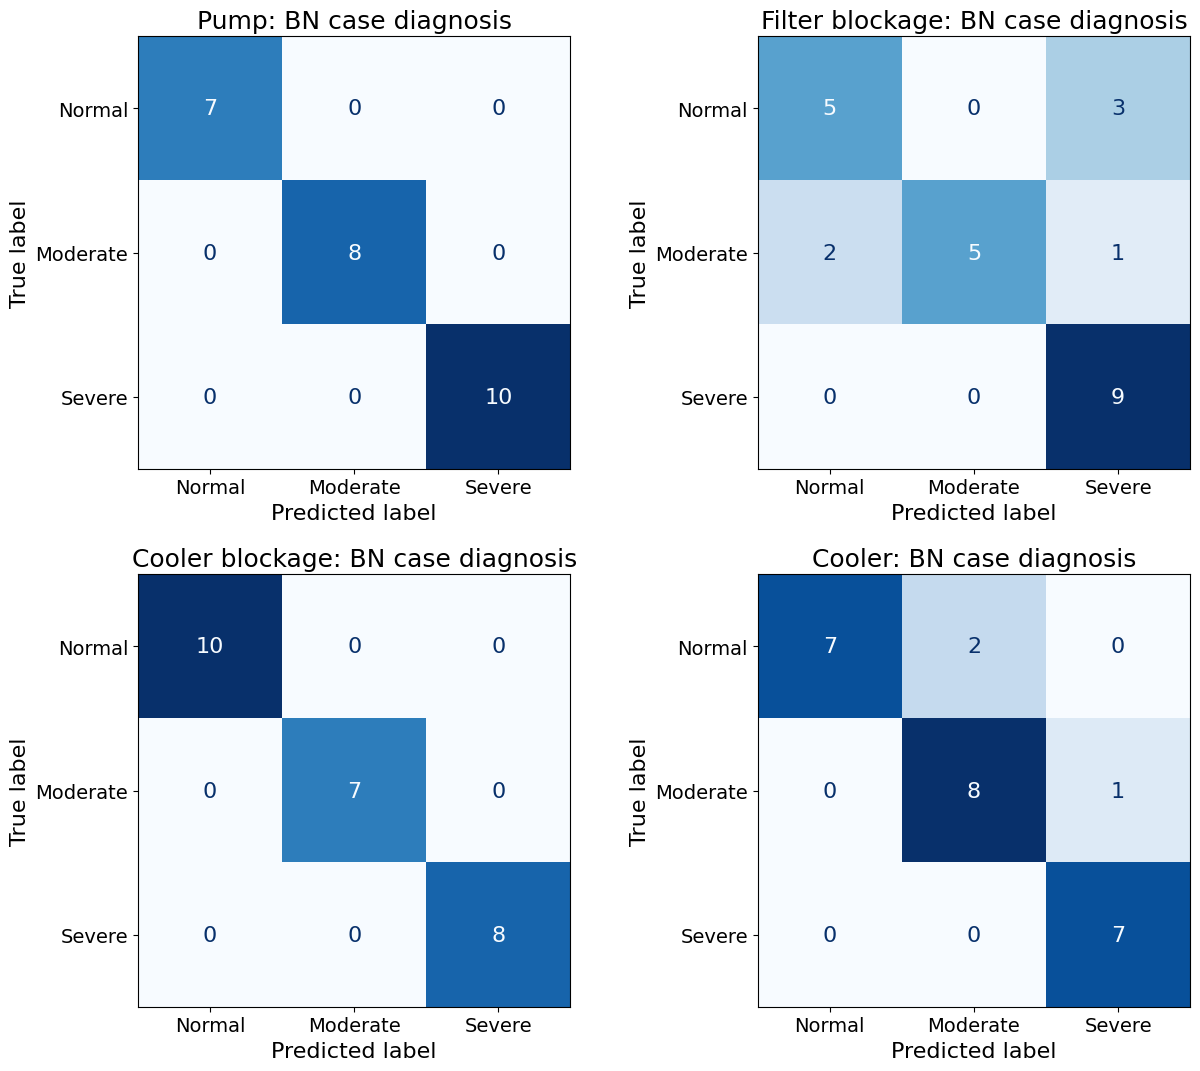

,Component,Accuracy
0,Pump,1.000
1,Filter blockage,0.760
2,Cooler blockage,1.000
3,Cooler,0.880


Case-level diagnosis accuracy by feature mode:


,Selected features
Pump,1.000
Filter blockage,0.760
Cooler blockage,1.000
Cooler,0.880


In [ ]:
# Standardize only selected features using training windows.
bn_training_features = bn_features[bn_train_cases].reshape(-1, bn_features.shape[-1])
bn_feature_mean = bn_training_features[:, bn_selected].mean(axis=0)
bn_feature_std = bn_training_features[:, bn_selected].std(axis=0)
bn_feature_std = np.where(bn_feature_std < 1e-8, 1.0, bn_feature_std)
bn_training_scaled = (bn_training_features[:, bn_selected] - bn_feature_mean) / bn_feature_std
bn_window_levels = np.repeat(bn_train_levels, n_windows, axis=0)

# Independent component priors permit unseen joint combinations, unlike an observed-states-only BN.
bn_states = np.array(list(product(range(3), repeat=4)), dtype=int)
bn_prior = np.ones(len(bn_states))
for j in range(4):
    counts = np.bincount(bn_train_levels[:, j], minlength=3)
    prior = (counts + 1.0) / (len(bn_train_cases) + 3)
    bn_prior *= prior[bn_states[:, j]]
bn_prior /= bn_prior.sum()

# Estimate conditional Gaussian densities with an explicit variance floor.
bn_cpds = []
for j, parents in enumerate(bn_selected_structure['Parents']):
    keys = bn_group_keys(bn_window_levels, parents)
    parameters = {}
    for key in range(3 ** len(parents)):
        values = bn_training_scaled[keys == key, j]
        assert len(values) > 0
        parameters[key] = (float(values.mean()), max(float(values.std()), BN_VARIANCE_FLOOR))
    bn_cpds.append((parents, parameters))

# Average per-window joint posteriors within each test; do not multiply correlated windows.
bn_posterior_cases = {}
bn_predictions_cases = {}
for name, ids in [('Validation', bn_val_cases), ('Test', bn_test_cases)]:
    posterior_windows = bn_infer(bn_features[ids].reshape(-1, bn_features.shape[-1]))
    posterior = posterior_windows.reshape(len(ids), n_windows, len(bn_states)).mean(axis=1)
    marginals = np.stack([np.column_stack([
        posterior[:, bn_states[:, j] == level].sum(axis=1) for level in range(3)])
        for j in range(4)], axis=1)
    predicted = marginals.argmax(axis=-1)
    bn_posterior_cases[name] = posterior
    bn_predictions_cases[name] = predicted
    print(name + ' mean component accuracy:', format_number(np.mean(predicted == bn_labels[ids])))
    print(name + ' exact four-component accuracy:', format_number(np.mean(np.all(predicted == bn_labels[ids], axis=1))))

# Report held-out component diagnosis at the independent-case level.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
bn_diagnosis_rows = []
for j, (name, ax) in enumerate(zip(fault_names, axes.ravel())):
    true, pred = bn_labels[bn_test_cases, j], bn_predictions_cases['Test'][:, j]
    cm = confusion_matrix(true, pred, labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Moderate', 'Severe']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(name + ': BN case diagnosis')
    bn_diagnosis_rows.append(dict(Component=name, Accuracy=accuracy_score(true, pred)))
plt.tight_layout(); plt.show()
display(pd.DataFrame(bn_diagnosis_rows))

# Retain results from both modes when rerun in the same runtime on the same data/settings.
import hashlib
bn_comparison_signature = hashlib.sha256(
    bn_features.tobytes() + bn_labels.tobytes() + bn_train_cases.tobytes() + bn_test_cases.tobytes()
    + str((BN_MAX_PARENTS, BN_MIN_CASES_PER_GROUP, BN_VARIANCE_FLOOR,
           BN_DELTA_BIC_MIN, BN_CORR_LIMIT, BN_MAX_FEATURES)).encode()).hexdigest()
if globals().get('bn_saved_comparison_signature') != bn_comparison_signature:
    bn_feature_comparison = {}
    bn_saved_comparison_signature = bn_comparison_signature
bn_mode_name = 'Selected features' if USE_FEATURE_SELECTION else 'All 44 features'
bn_feature_comparison[bn_mode_name] = {row['Component']: row['Accuracy'] for row in bn_diagnosis_rows}
print('Case-level diagnosis accuracy by feature mode:')
display(pd.DataFrame(bn_feature_comparison).reindex(fault_names))


## Estimate bearing responses through the component posterior

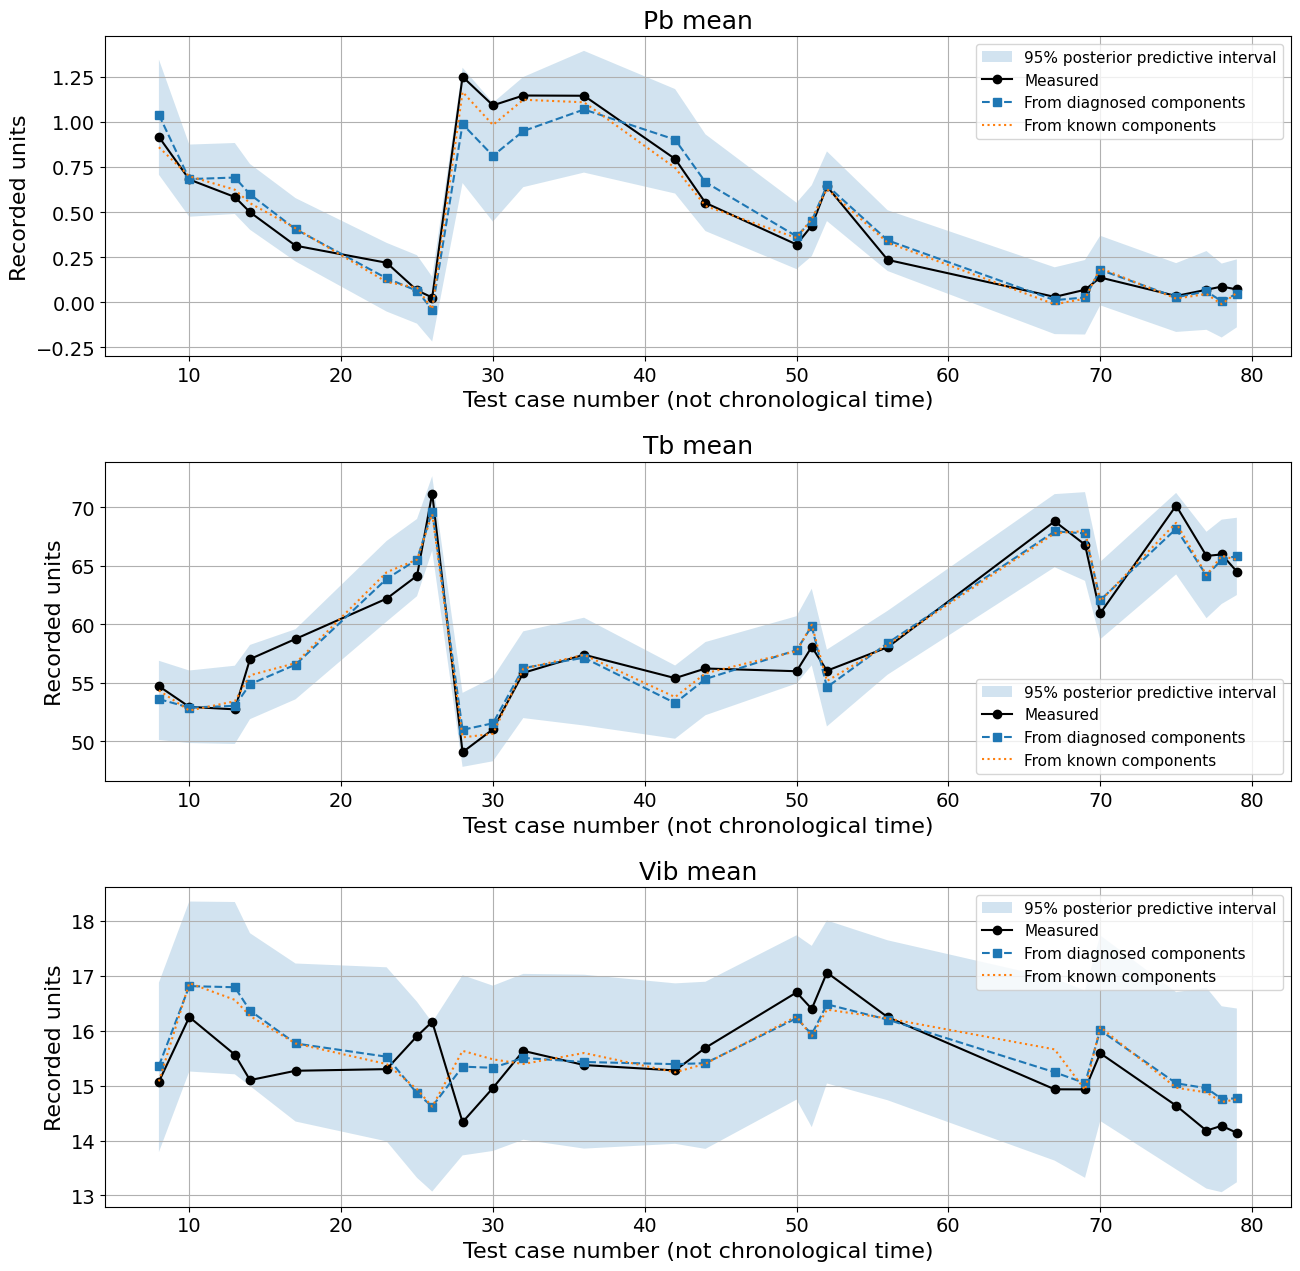

,Target,Inferred_components_RMSE,Known_components_RMSE,Training_mean_baseline_RMSE,R2,Predictive_interval_coverage
0,Pb mean,0.109,0.059,0.400,0.924,1.000
1,Tb mean,1.378,1.237,6.084,0.947,1.000
2,Vib mean,0.663,0.672,0.801,0.260,0.960


,Case,Pump,Filter blockage,Cooler blockage,Cooler,Pump predicted severity,Filter blockage predicted severity,Cooler blockage predicted severity,Cooler predicted severity,Pb mean measured,...,Pb mean lower95,Pb mean upper95,Tb mean measured,Tb mean estimated,Tb mean lower95,Tb mean upper95,Vib mean measured,Vib mean estimated,Vib mean lower95,Vib mean upper95
4,8,0,2,0,1,0,2,0,1,0.916,...,0.707,1.345,54.71,53.61,50.12,56.88,15.07,15.36,13.79,16.88
2,10,1,0,0,0,1,0,0,0,0.681,...,0.474,0.874,52.95,52.89,49.86,56.05,16.25,16.81,15.26,18.35
3,13,1,1,0,0,1,0,0,0,0.583,...,0.489,0.883,52.73,53.03,49.78,56.46,15.57,16.79,15.21,18.35
16,14,1,1,1,1,1,0,1,1,0.499,...,0.402,0.766,57.02,54.88,51.89,58.23,15.10,16.37,14.99,17.78
17,17,1,2,1,1,1,2,1,1,0.314,...,0.226,0.577,58.74,56.55,53.59,59.58,15.27,15.77,14.35,17.23
13,23,2,1,0,2,2,1,0,2,0.219,...,-0.052,0.329,62.19,63.88,60.23,67.11,15.30,15.53,13.99,17.16
7,25,2,2,1,0,2,2,1,1,0.066,...,-0.119,0.261,64.14,65.52,62.39,68.98,15.90,14.86,13.32,16.53
12,26,2,2,2,1,2,2,2,2,0.026,...,-0.218,0.141,71.16,69.61,66.28,72.63,16.16,14.62,13.07,16.15
23,28,0,0,0,0,0,2,0,0,1.250,...,0.661,1.300,49.08,50.99,47.82,54.14,14.34,15.35,13.73,17.01
24,30,0,0,1,0,0,2,1,0,1.092,...,0.447,1.106,51.03,51.54,48.30,55.45,14.96,15.33,13.81,16.82


In [ ]:
# User settings: Bayesian quadratic regression prior and posterior sampling.
BN_PRIOR_VARIANCE = 10.0
BN_INTERVAL_DRAWS = 4000
BN_RANDOM_STATE = 42

# Targets are complete-record means, not bearing fault labels or a fabricated HI.
bn_target_names = ['Pb mean', 'Tb mean', 'Vib mean']
bn_system_targets = data[:, bearing_idx, :].mean(axis=0).T.astype(float)
bn_target_mean = bn_system_targets[bn_train_cases].mean(axis=0)
bn_target_std = bn_system_targets[bn_train_cases].std(axis=0)
bn_target_std = np.where(bn_target_std < 1e-8, 1.0, bn_target_std)
bn_y_train = (bn_system_targets[bn_train_cases] - bn_target_mean) / bn_target_std
bn_design = bn_system_basis(bn_train_levels)
bn_state_design = bn_system_basis(bn_states)
bn_precision0 = np.eye(bn_design.shape[1]) / BN_PRIOR_VARIANCE
bn_reg_cov = np.linalg.inv(bn_precision0 + bn_design.T @ bn_design)
bn_reg_beta = bn_reg_cov @ bn_design.T @ bn_y_train
bn_reg_a = 2.0 + len(bn_train_cases) / 2.0
bn_reg_b = 0.1 + 0.5 * (np.sum(bn_y_train ** 2, axis=0)
    - np.sum(bn_reg_beta * ((bn_precision0 + bn_design.T @ bn_design) @ bn_reg_beta), axis=0))
assert np.all(bn_reg_b > 0)

# State-conditional Student-t prediction includes parameter and response-noise uncertainty.
bn_state_mean = bn_state_design @ bn_reg_beta
bn_leverage = np.sum((bn_state_design @ bn_reg_cov) * bn_state_design, axis=1)
bn_state_scale = np.sqrt((1 + bn_leverage[:, None]) * bn_reg_b[None, :] / bn_reg_a)
bn_system_pred = (bn_posterior_cases['Test'] @ bn_state_mean) * bn_target_std + bn_target_mean
bn_system_oracle = (bn_system_basis(bn_labels[bn_test_cases]) @ bn_reg_beta) * bn_target_std + bn_target_mean

# Integrate the full diagnosed joint posterior, rather than plugging in only the winning classes.
np.random.seed(BN_RANDOM_STATE)
bn_system_lower = np.empty_like(bn_system_pred)
bn_system_upper = np.empty_like(bn_system_pred)
for i, posterior in enumerate(bn_posterior_cases['Test']):
    state_draws = np.random.choice(len(bn_states), BN_INTERVAL_DRAWS, p=posterior)
    response_draws = (bn_state_mean[state_draws]
        + np.random.standard_t(2 * bn_reg_a, size=(BN_INTERVAL_DRAWS, 3)) * bn_state_scale[state_draws])
    response_draws = response_draws * bn_target_std + bn_target_mean
    bn_system_lower[i], bn_system_upper[i] = np.quantile(response_draws, [0.025, 0.975], axis=0)

# Separate component-inference error from system-response regression error.
from sklearn.metrics import r2_score
bn_system_rows = []
bn_true_system = bn_system_targets[bn_test_cases]
fig, axes = plt.subplots(3, 1, figsize=(13, 13))
order = np.argsort(bn_test_cases)
for j, (name, ax) in enumerate(zip(bn_target_names, axes)):
    actual, predicted = bn_true_system[:, j], bn_system_pred[:, j]
    bn_system_rows.append(dict(Target=name,
        Inferred_components_RMSE=np.sqrt(np.mean((actual - predicted) ** 2)),
        Known_components_RMSE=np.sqrt(np.mean((actual - bn_system_oracle[:, j]) ** 2)),
        Training_mean_baseline_RMSE=np.sqrt(np.mean((actual - bn_target_mean[j]) ** 2)),
        R2=r2_score(actual, predicted),
        Predictive_interval_coverage=np.mean((actual >= bn_system_lower[:, j]) & (actual <= bn_system_upper[:, j]))))
    case_axis = bn_test_cases[order] + 1
    ax.fill_between(case_axis, bn_system_lower[order, j], bn_system_upper[order, j], alpha=0.2,
                    label='95% posterior predictive interval')
    ax.plot(case_axis, actual[order], 'ko-', label='Measured')
    ax.plot(case_axis, predicted[order], 's--', label='From diagnosed components')
    ax.plot(case_axis, bn_system_oracle[order, j], ':', label='From known components')
    ax.set(title=name, xlabel='Test case number (not chronological time)', ylabel='Recorded units')
    ax.legend(fontsize=11); ax.grid(True)
plt.tight_layout(); plt.show()
display(pd.DataFrame(bn_system_rows))

# Provide case-level component estimates and system responses for inspection.
bn_case_report = case_table.iloc[bn_test_cases].copy().reset_index(drop=True)
for j, name in enumerate(fault_names):
    bn_case_report[name + ' predicted severity'] = bn_predictions_cases['Test'][:, j]
for j, name in enumerate(bn_target_names):
    bn_case_report[name + ' measured'] = bn_true_system[:, j]
    bn_case_report[name + ' estimated'] = bn_system_pred[:, j]
    bn_case_report[name + ' lower95'] = bn_system_lower[:, j]
    bn_case_report[name + ' upper95'] = bn_system_upper[:, j]
display(bn_case_report.sort_values('Case'))


## Inspect a held-out case

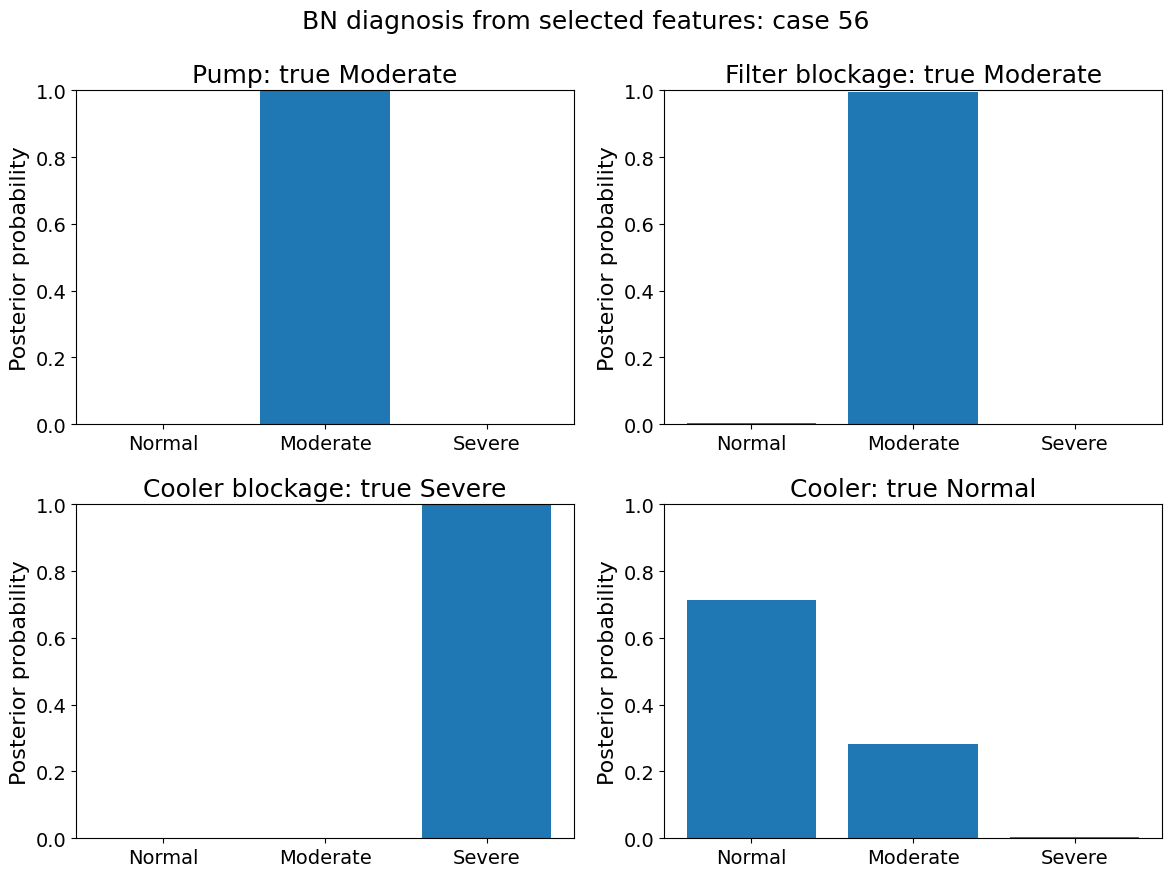

,Case,Pump,Filter blockage,Cooler blockage,Cooler,Pump predicted severity,Filter blockage predicted severity,Cooler blockage predicted severity,Cooler predicted severity,Pb mean measured,...,Pb mean lower95,Pb mean upper95,Tb mean measured,Tb mean estimated,Tb mean lower95,Tb mean upper95,Vib mean measured,Vib mean estimated,Vib mean lower95,Vib mean upper95
0,56,1,1,2,0,1,1,2,0,0.235,...,0.173,0.510,58.04,58.39,55.69,61.15,16.25,16.20,14.73,17.65


In [ ]:
# User settings: inspect one held-out case's component posterior and bearing response.
BN_EXAMPLE_CASE_ID = int(bn_test_cases[0] + 1)
example_position = np.flatnonzero(bn_test_cases == BN_EXAMPLE_CASE_ID - 1)
assert len(example_position) == 1, 'Choose a case from bn_test_cases + 1.'
example_position = int(example_position[0])
posterior = bn_posterior_cases['Test'][example_position]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for j, (name, ax) in enumerate(zip(fault_names, axes.ravel())):
    probabilities = np.array([posterior[bn_states[:, j] == level].sum() for level in range(3)])
    ax.bar(['Normal', 'Moderate', 'Severe'], probabilities)
    true_level = ['Normal', 'Moderate', 'Severe'][bn_labels[BN_EXAMPLE_CASE_ID - 1, j]]
    ax.set(title=f'{name}: true {true_level}', ylabel='Posterior probability', ylim=(0, 1))
plt.suptitle(f'BN diagnosis from selected features: case {BN_EXAMPLE_CASE_ID}')
plt.tight_layout(); plt.show()
display(bn_case_report.loc[bn_case_report['Case'] == BN_EXAMPLE_CASE_ID])


## Inspect the fitted BN structure
Arrows show the generative model, not the direction of diagnostic computation. The system-response CPDs use all four component states and pairwise quadratic interactions.

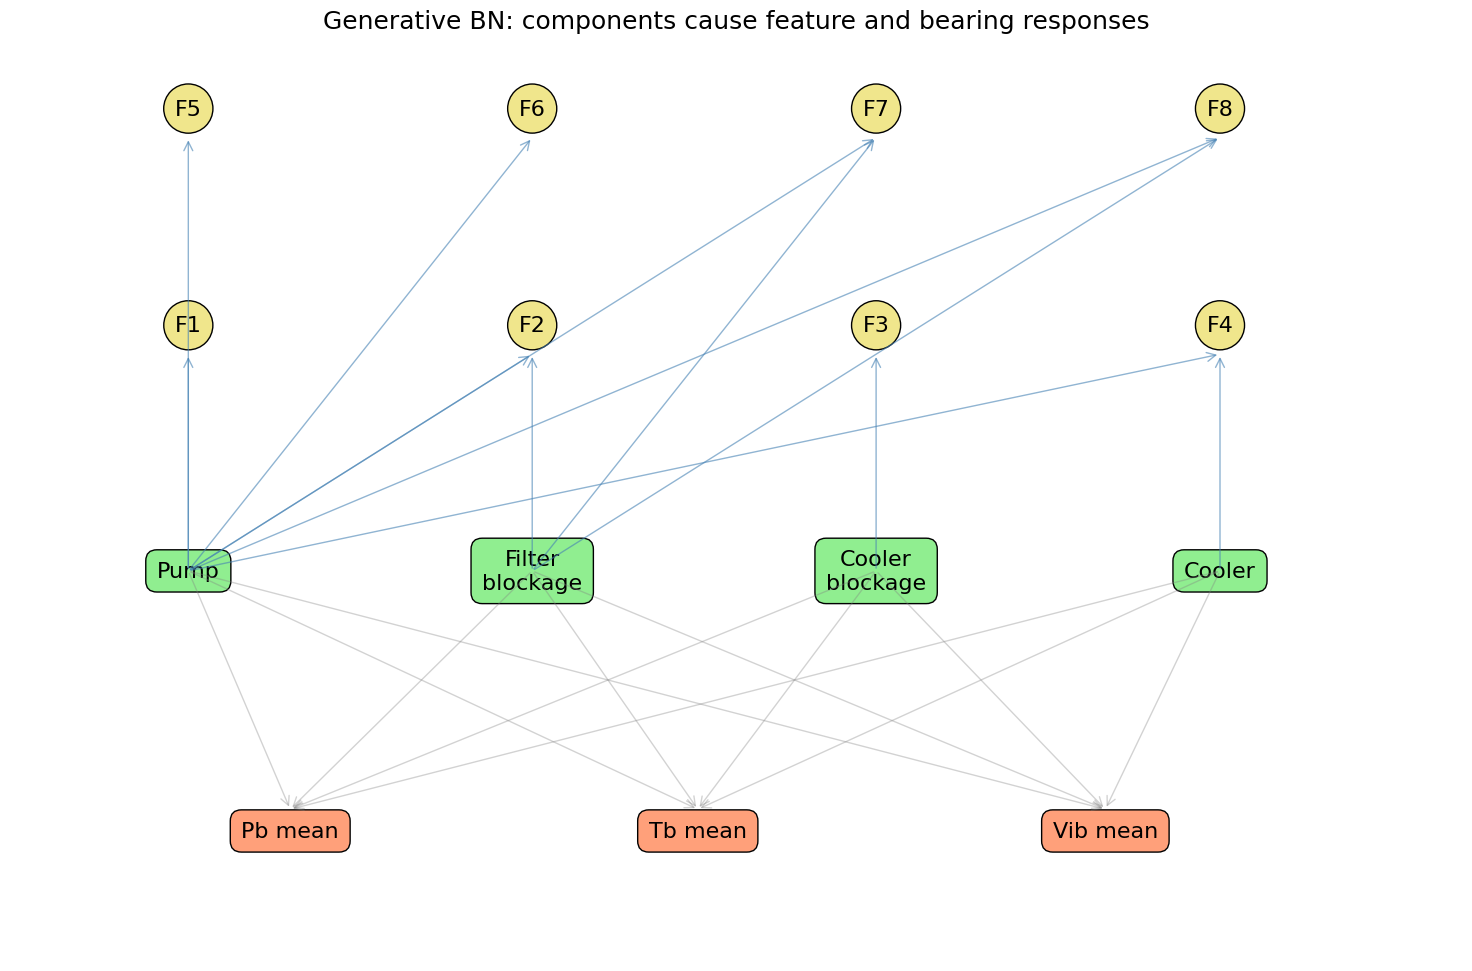

,Feature,Parent_components,Node
0,P2-STD,Pump,F1
1,P1-STD,Pump + Filter blockage,F2
2,Cooler (P3-P4)/Q^2-Mean,Cooler blockage,F3
3,Cooling Q*(T3-T4)-Mean,Pump + Cooler,F4
4,Pump P2-P1-Mean,Pump,F5
5,Pump Q*(P2-P1)-Mean,Pump,F6
6,P3-STD,Pump + Filter blockage,F7
7,Cooler (P3-P4)/Q-STD,Pump + Filter blockage,F8


In [ ]:
# Display causal BN edges; inference uses these edges in reverse for diagnosis.
feature_rows = int(np.ceil(len(bn_selected_structure) / 4))
fig, ax = plt.subplots(figsize=(15, max(10, 2 + 1.5 * feature_rows)))
component_positions = {j: (j * 2.7, 1.3) for j in range(4)}
for j, name in enumerate(fault_names):
    x, y = component_positions[j]
    ax.text(x, y, name.replace(' ', '\n'), ha='center', va='center',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='lightgreen'))
for k, row in enumerate(bn_selected_structure.itertuples()):
    x, y = (k % 4) * 2.7, 3.0 + 1.5 * (k // 4)
    ax.text(x, y, f'F{k + 1}', ha='center', va='center',
            bbox=dict(boxstyle='circle,pad=0.5', facecolor='khaki'))
    for parent in row.Parents:
        ax.annotate('', xy=(x, y - 0.2), xytext=component_positions[parent],
                    arrowprops=dict(arrowstyle='->', color='steelblue', alpha=0.6))
for j, name in enumerate(bn_target_names):
    x, y = 0.8 + 3.2 * j, -0.5
    ax.text(x, y, name, ha='center', va='center',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='lightsalmon'))
    for parent in range(4):
        ax.annotate('', xy=(x, y + 0.15), xytext=component_positions[parent],
                    arrowprops=dict(arrowstyle='->', color='gray', alpha=0.35))
ax.set(xlim=(-1.4, 10), ylim=(-1.4, 3.5 + 1.5 * (feature_rows - 1)), title='Generative BN: components cause feature and bearing responses')
ax.axis('off'); plt.tight_layout(); plt.show()
display(bn_selected_structure[['Feature', 'Parent_components']].assign(
    Node=[f'F{k + 1}' for k in range(len(bn_selected_structure))]))
